# Blind retrieval, light curve `lc_b`: a giant planet on a 91-day orbit

This is one of six light curves of a **blind injection-retrieval test**: Nicholas Jannsen simulated PLATO-like
light curves, some (or none) with an exomoon, and sent us the light curves only. We do not know what was injected,
nor which instrumental effects or stellar signals were added. Here we analyse `lc_b` with Pandora, from the raw data
to a Bayes factor and a physical interpretation, in the order one would do it with real data.

We use two routes for the stellar and instrumental trends, and compare them:

- **A, biweight:** detrend the light curve with a robust filter (wotan's biweight, transits masked), then fit the
  transit model with white-noise errors;
- **B, simultaneous GP:** fit the raw flux as transit model + Gaussian process + white noise.

For each route we run the fast detection test `pandora.detect` (seconds) and the full fit `pandora.NestedSampler`
(minutes on a GPU), which gives the evidence of the planet-only and the planet+moon model and the posteriors.

**Contents:** 1. the data and their problems; 2. a model-free look at the transits; 3. priors; 4. cleaning;
5. route A (biweight); 6. route B (GP); 7. the evidence; 8. figures; 9. the physics of the planet+moon solution;
10. further checks (audit, injection-retrieval tests); 11. assessment and learnings.

## 0. Set-up

This notebook needs `pandoramoon` with its optional parts (`pip install "pandoramoon[gpu,plots,search]"` and, for the
GPU, `pip install "numba-cuda[cu13]"`), `pandas` and `pyarrow` (to read the feather files). `blind.py` (in this folder)
holds the helper functions shared by the six notebooks: loading, data checks, the noise model, the two light-curve
preparations and the plots. Every Pandora call is in this notebook.

The full fits run on the GPU (`DEVICE = "gpu"`); `DEVICE = "cpu"` gives the same results, slower. `THREADS` limits the
CPU cores (detection, the planet-only fit, the GP profile). Every fit is stored in `results/`. With `REFIT = False`
(default) the notebook reads the stored fits (`blind.load_fit`: the results Pandora wrote, checked against the current
data and priors; no sampler, no GPU) and runs in a few minutes; it fits only what is not stored yet. With
`REFIT = True` it runs the fits again.

In [1]:
%matplotlib inline
import time as timer
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = [12, 4]

import pandoramoon as pandora
from pandoramoon.gp import GP
import blind

NAME = "b"                # light curve lc_b.ftr
DEVICE = "gpu"            # "cpu" works too (slower)
import os
THREADS = int(os.environ.get("BLIND_THREADS", 5))     # CPU threads (detect, planet-only fits, GP profile)
# REFIT = False: read the stored fits from results/ (no sampler, no GPU); fit only what is not stored yet.
# REFIT = True: run the full fits again (resume="resume" reuses Pandora's stored runs where the data are unchanged)
REFIT = bool(int(os.environ.get("BLIND_REFIT", "0")))
RESULTS = f"results/lc_{NAME}"
from pandoramoon.version import PANDORA_VERSIONING
print("pandoramoon", PANDORA_VERSIONING)

pandoramoon 2.1


## 1. The data, and what is wrong with them

A blind test: we were given the light curve only. The files hold time [s] and flux normalised to 1. Before any fit
we look for the problems a real (or a realistically simulated) light curve has: gaps, jumps between segments, ramps
after gaps, outliers and flares, and a noise level that changes with time. `blind.data_checks` prints a table per
continuous segment; `blind.plot_checks` shows the light curve, the noise level over time, and the flux in the first
and last three days of every segment.

104044 points, cadence 600.004 s, span 729.48 d, 8 segments
segment      start      end       N   mean [ppm]  sigma [ppm/cadence]  slope [ppm/d]
   0       0.00     90.31   13005       -0.8         42.5            -0.039
   1      91.31    181.62   13006       +1.2         47.2            -0.016
   2     182.62    272.93   13005       -1.5         43.3            -0.062
   3     273.93    364.24   13006       +2.0         44.0            -0.021
   4     365.24    455.56   13006       -1.2         43.8            -0.031
   5     456.56    546.86   13005       +1.0         45.9            -0.028
   6     547.86    638.17   13006       -0.3         44.6            -0.026
   7     639.17    729.48   13005       +1.5         46.2            -0.019
jumps across the gaps (12 h after minus 12 h before) [ppm]: +49±8, +57±8, +57±7, +33±7, +72±7, +45±7, +51±7
first 1 d of each segment vs its middle: mean +17.6 ppm (each: +19, +18, +17, +17, +17, +27, +13, +14)
last  1 d of each segment vs its mid

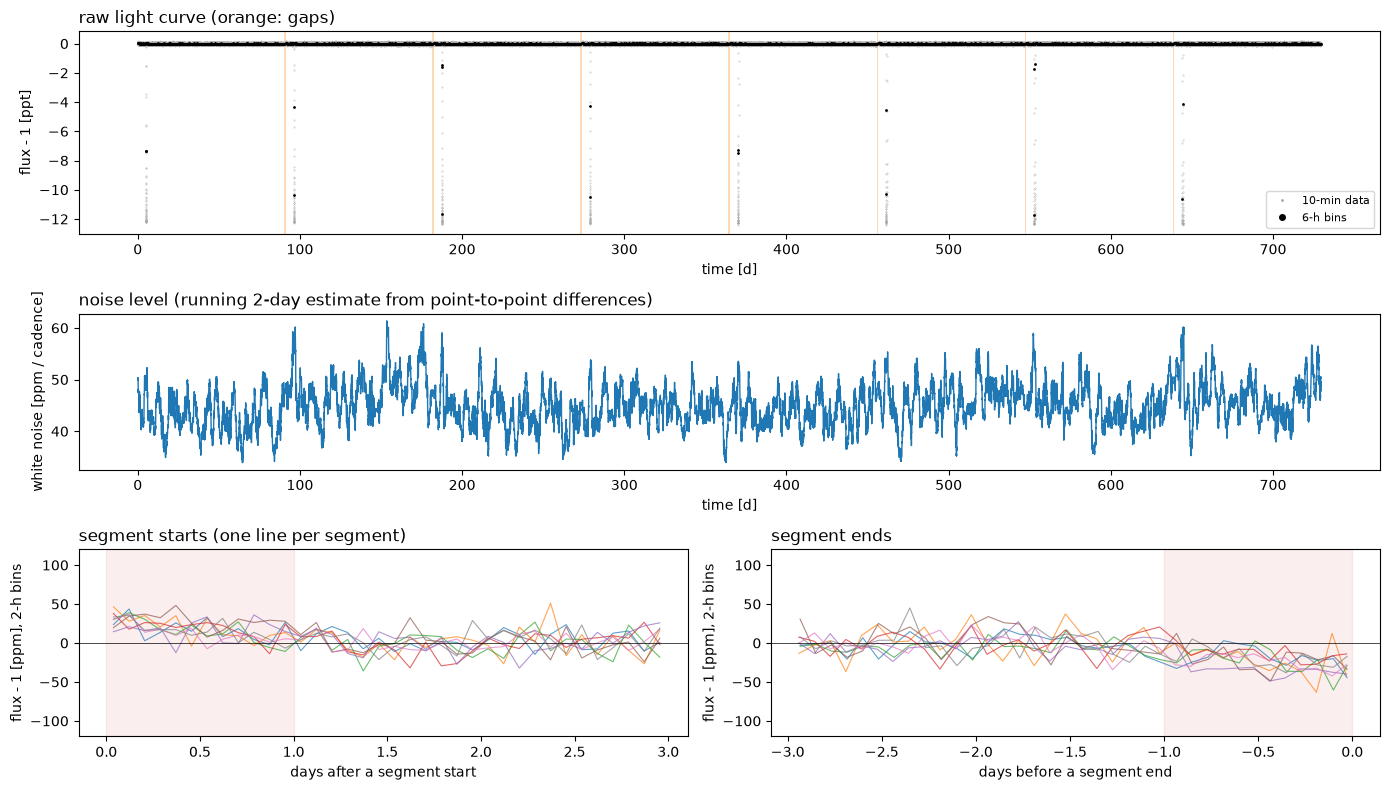

In [2]:
t, f = blind.load(NAME)
checks = blind.data_checks(t, f)
blind.plot_checks(t, f, checks)
plt.show()

**What the checks show.** The common instrument signature of the six light curves:

- 10-min cadence, 8 segments of 91.3 days with 1-day gaps;
- segment means within ±2 ppm;
- ramps at the segment edges (+18 ppm after a gap, −22 ppm before one), jumps of +33 to +72 ppm across the gaps.

The noise is 42–47 ppm per point, nearly constant between segments. Neighbouring points are weakly correlated
(+0.03), the tails slightly heavy (+0.11), with one point beyond 5σ. No flares, spots or stellar variability.

## 2. A first look at the transits (no model)

We find the transits without a model: runs of points more than 5σ below 1, their mid-times (half-depth crossings),
the period and epoch of a linear ephemeris, the depth and the total duration T14 (from the stack of all transits).
These numbers only centre the priors and set the windows; the fits determine them properly.

In [3]:
ft = blind.find_transits(t, f, checks["sigma"])
T14 = blind.transit_duration(t, f, ft, checks["sigma"])
P, T0 = ft["P"], ft["T0"]
print(f"{len(ft['tmid'])} transits at t = {np.round(ft['tmid'], 3)} d")
print(f"P = {P:.5f} d, T0 = {T0:.5f} d, depth = {1e6 * ft['depth']:.0f} ppm, T14 = {24 * T14:.2f} h")
oc = 1440 * (ft["tmid"] - (T0 + P * ft["epoch"]))
print("mid-times minus the linear ephemeris [min]:", np.round(oc, 2))
print("half-depth durations [min]:", np.round(1440 * ft["dur_half"], 1))
HALF_LOOK = min(1.0, 0.45 * P)          # half-width of the plots below [d]

8 transits at t = [  5.     96.312 187.625 278.938 370.25  461.562 552.875 644.188] d
P = 91.31254 d, T0 = 4.99973 d, depth = 12220 ppm, T14 = 9.00 h
mid-times minus the linear ephemeris [min]: [ 0.32 -0.17 -0.45  0.5   0.1  -0.5  -0.29  0.49]
half-depth durations [min]: [463.  462.5 463.1 463.  463.8 464.1 464.2 463.7]


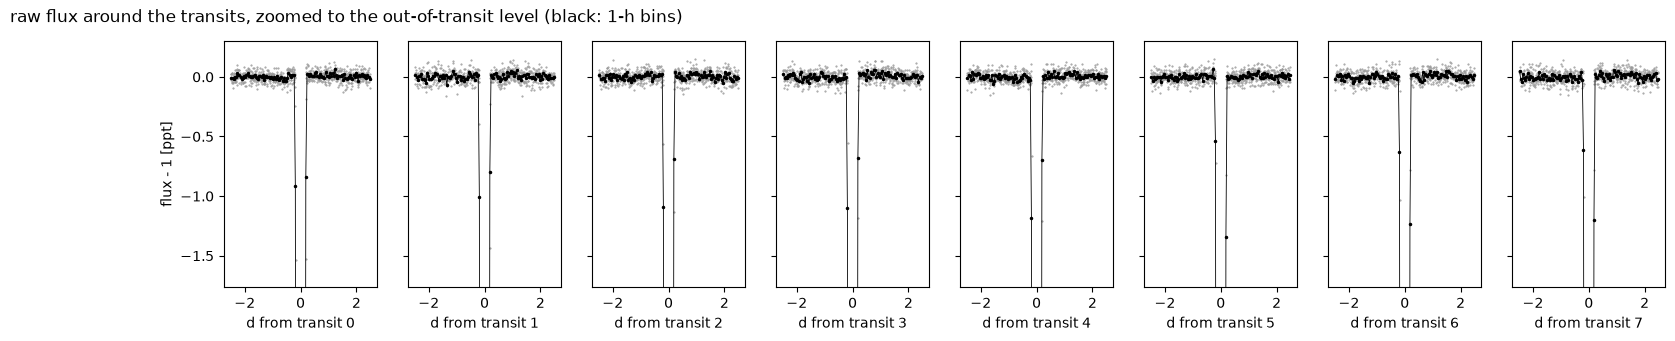

In [4]:
n_show = min(len(ft["tmid"]), 8)
fig, axs = plt.subplots(1, n_show, figsize=(2.2 * n_show + 1, 3.2), sharey=True, squeeze=False)
for k, ax in enumerate(axs[0]):
    tc = ft["tmid"][k]
    m = np.abs(t - tc) < 2.5
    ax.plot(t[m] - tc, 1e3 * (f[m] - 1), ".", ms=1, color="0.6")
    xb, yb, _ = blind.binned(t[m] - tc, f[m], 1 / 24)
    ax.plot(xb, 1e3 * (yb - 1), "k.-", ms=3, lw=0.6)
    ax.set_ylim(-0.12 * 1e3 * ft["depth"] - 0.3, 0.3)
    ax.set_xlabel(f"d from transit {ft['epoch'][k]}")
axs[0, 0].set_ylabel("flux - 1 [ppt]")
plt.suptitle("raw flux around the transits, zoomed to the out-of-transit level (black: 1-h bins)", x=0.01, ha="left")
plt.show()

**Do the transits differ?** Before any model: we align the transits on the linear ephemeris and subtract them from
each other (two transits) or from their median (more transits). A moon shows up as dips that move from transit to
transit, and as changes of the transit's timing and duration (the planet wobbles around the planet-moon
barycentre). Spot crossings would show as short bumps *inside* the transit, instrumental steps as offsets.

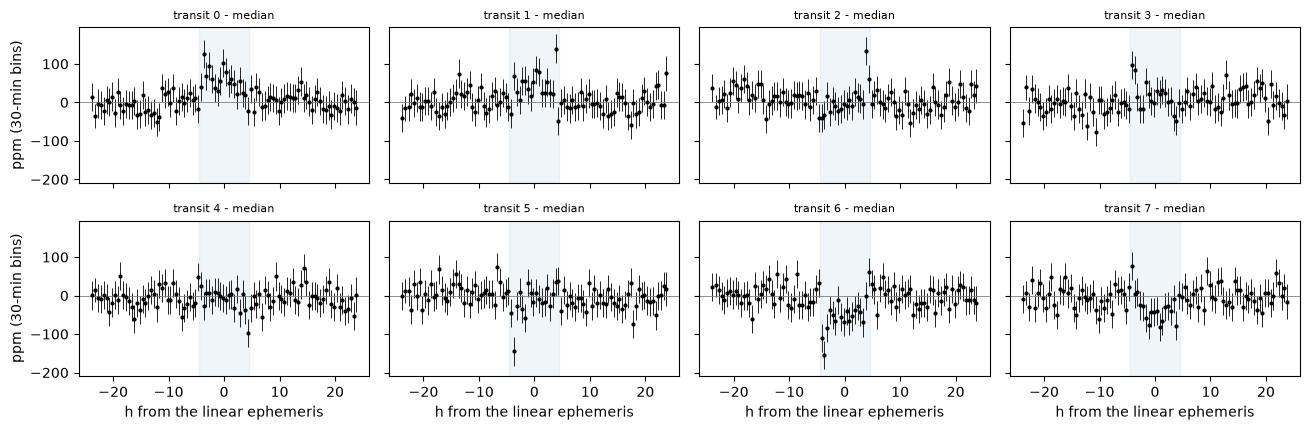

In [5]:
grid = np.arange(-HALF_LOOK, HALF_LOOK, 600 / 86400)
stack = np.array([np.interp(grid, t[np.abs(t - (T0 + P * e)) < HALF_LOOK + 0.1] - (T0 + P * e),
                            f[np.abs(t - (T0 + P * e)) < HALF_LOOK + 0.1]) for e in ft["epoch"]])
ref = stack[0] if len(stack) == 2 else np.median(stack, axis=0)
show_e = range(1, 2) if len(stack) == 2 else range(len(stack))
n_cols = 1 if len(stack) == 2 else min(len(stack), 4)
n_rows = int(np.ceil(len(show_e) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(12 if n_cols == 1 else 3.3 * n_cols, 3.2 * n_rows if n_cols == 1
                        else 2.2 * n_rows), sharex=True, sharey=True, squeeze=False)
sig_med = np.median(checks["sigma"])
for ax, i in zip(axs.flat, show_e):
    xb, db, nb = blind.binned(grid * 24, stack[i] - ref, 0.5)
    ax.errorbar(xb, 1e6 * db, 1e6 * sig_med * np.sqrt(2) / np.sqrt(nb), fmt="o", ms=2, color="k", elinewidth=0.6)
    ax.axhline(0, color="0.5", lw=0.6)
    ax.axvspan(-12 * T14, 12 * T14, color="C0", alpha=0.07)
    ax.set_title(f"transit {ft['epoch'][i]} - " + ("transit 0" if len(stack) == 2 else "median"), fontsize=8)
for ax in axs[-1]:
    ax.set_xlabel("h from the linear ephemeris")
for ax in axs[:, 0]:
    ax.set_ylabel("ppm (30-min bins)")
for ax in axs.flat[len(show_e):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Eight transits, 91.3 days apart** (P = 91.3125 d), 12 200 ppm deep and 9.0 hours long: a Jupiter-size planet on a
91-day orbit (~0.4 AU around a Sun-like star), the same orbit as lc_d's planet, but larger.

**The transits are not alike.**

- **Depth:** the differences from the median transit show a clear pattern. The first transits are ~60 ppm shallower
  than the median, the last ones ~60 ppm deeper, with no dips beside the transits. A model-free fit gives
  **+16.2 ± 1.6 ppm per transit** (10σ), a smooth deepening over two years.
- **Timing:** the model-free mid-times scatter by ±0.5 min, within their rough errors. A fit of each transit with the
  planet's own shape (section 10) is ~5× more precise (±0.08 min) and finds **transit-timing variations** of ±0.4 min.
- **Duration:** the total duration T14 stays at 539–540 min. (The half-depth duration grows, because the transit
  deepens.)

A moon's own dips would move from transit to transit; the deepening is a slow, monotonic change of the transit itself.
The timing variations are what a moon's pull on its planet produces.

## 3. Priors, and how far from the planet a moon can be

We use Pandora's `default_priors` (the priors the detection test was calibrated with), centred on the ephemeris
above. The moon priors are: radius 0.1–0.7 × the planet's, period up to 0.19 × the planet's period (the prograde
stability limit at ~0.48 Hill radii), mass up to half the planet's, all orientations.

The moon can transit up to `reach` days before or after its planet: its largest orbit (the longest prior period,
the heaviest prior planet) divided by the planet's speed. The fit windows must cover the transit and this reach,
otherwise a moon's dip can fall outside the data.

In [6]:
r_planet = float(np.sqrt(ft["depth"]))      # first guess of R_planet / R_star (limb darkening makes it ~5 % too large)
priors = pandora.default_priors(t0_bary=round(T0, 2), per_bary=P, r_planet=r_planet)   # Jupiter-mass planet (default)

In [7]:
for name, prior in priors.items():
    print(f"  {name:16s} {prior}")
reach = blind.moon_reach(P, priors["per_moon"].hi, priors["M_planet"].hi)
HALF = reach["reach_days"] + T14          # half-width of the fit windows [d]
print(f"largest moon orbit {reach['a_moon_max']:.2f} R_star = {reach['reach_days']:.2f} d of planet motion "
      f"(Hill radius {reach['r_hill']:.1f} R_star = {reach['hill_days']:.2f} d); fit windows: +-{HALF:.2f} d")

  q1               Uniform(lo=0.0, hi=1.0)
  q2               Uniform(lo=0.0, hi=1.0)
  R_star           Uniform(lo=557073600.0, hi=835610400.0)
  per_bary         Uniform(lo=91.12991946550937, hi=91.49516964372785)
  a_bary           LogUniform(lo=34.11315488331988, hi=213.20721802074925)
  r_planet         Uniform(lo=0.055273109854360486, hi=0.16581932956308146)
  b_bary           Uniform(lo=0.0, hi=1.0)
  t0_bary          5.0
  t0_bary_offset   Uniform(lo=-0.05, hi=0.05)
  M_planet         Uniform(lo=9.49065e+26, hi=2.847195e+27)
  r_moon           Uniform(lo=0.011054621970872099, hi=0.07738235379610467)
  per_moon         Uniform(lo=0.0, hi=17.349)
  tau_moon         Uniform(lo=0.0, hi=1.0)
  Omega_moon       Uniform(lo=0.0, hi=180.0)
  i_moon           Uniform(lo=0.0, hi=180.0)
  M_moon           Uniform(lo=0.0, hi=9.49065e+26)
largest moon orbit 3.18 R_star = 0.54 d of planet motion (Hill radius 6.7 R_star = 1.14 d); fit windows: +-0.92 d


**Priors and windows.** The default priors of a Jupiter-mass planet. At 91 days the widest prior moon orbit (17-day
period) reaches 0.54 days from the planet; fit windows ±0.92 days (2110 points in 8 windows).

## 4. Noise near the transits, segment edges and outliers

Three decisions, the same for both routes:

- **The noise level near the transits.** The running estimate of section 1 uses differences of neighbouring points.
  A deep transit's ingress and egress are steep steps that make large differences; they raise the running median by
  15–20 % within a day of a deep transit, exactly where the error bars matter. (We found this only after a first
  round of fits: their errors were too large near the transits, so their Bayes factors were too small.) So we
  estimate it again with the transits left out and interpolate across them.

- **Segment edges:** the flux drifts by tens of ppm in the first and last day of each segment (section 1). We leave
  out 1 day at each segment edge (2 % of the data). This affects only transit windows that touch a gap.
- **Outliers and flares:** `GP.fit(..., clip=True)` flags points above 4σ everywhere (flares), below 5σ outside the
  transit windows, and isolated one-cadence dips inside them, against the GP's own prediction. We fit the GP's
  hyperparameters here (section 6 explains them) and use its flags in both routes.

In [8]:
# the white-noise level near the transits: the running estimate of section 1 with the transits left out
in_transit = blind.phase_distance(t, T0, P) < 0.5 * T14 + 0.02
sigma = blind.local_sigma(t, f, mask=in_transit)
near = (blind.phase_distance(t, T0, P) < 0.5 * T14 + T14) & ~in_transit     # within one T14 of the transits
print(f"noise near the transits: {1e6 * np.median(sigma[near]):.1f} ppm per cadence; the estimate with the "
      f"transits included was {100 * (np.median(checks['sigma'][near] / sigma[near]) - 1):+.0f} % higher there")
edges = blind.edge_mask(t, edge=1.0)
t_start = timer.time()
# cache: GP.fit's last digits differ between CPUs; the stored hyperparameters make the data bit-identical on any
# machine, so the stored fits below are reused (resume) instead of refitted
gp, gpw, outliers = blind.prepare_gp(t, f, sigma, T0, P, HALF, bad=edges,
                                     kernel="sho", baseline="offset", gap=0.5, clip=True,
                                     cache=f"{RESULTS}/gp_hyper.npz")
bad = edges | outliers
print(f"GP hyperparameters ({'stored' if timer.time() - t_start < 1 else 'GP.fit'}, {timer.time() - t_start:.0f} s): {gp}")
print(f"left out: {edges.sum()} points at segment edges, {outliers.sum()} outliers / flares at t =",
      np.round(t[outliers], 2))
in_win = blind.phase_distance(t, T0, P) < HALF
print(f"outliers inside the fit windows: {(outliers & in_win).sum()}")

noise near the transits: 43.4 ppm per cadence; the estimate with the transits included was +22 % higher there
GP hyperparameters (stored, 0 s): GP(amp=9.84414e-06, tau=0.00694449, Q=0.707107, err_scale=0.990442, baseline='offset', gap=0.5)
left out: 2304 points at segment edges, 9 outliers / flares at t = [128.76 276.28 283.86 321.06 329.08 353.28 440.71 495.99 718.84]
outliers inside the fit windows: 0


**Cleaning.** The noise estimate with the transits included was 22 % too high near these deep transits; we use the one
without them. The segment edges cost 2 % of the points, none in a fit window. Nine single-point outliers, none in a fit
window.

## 5. Route A: biweight detrending + white-noise fit

The classical route. `pandora.prepare_lightcurve` detrends with wotan's robust `biweight`: the transits are masked
over 1.0 × T14 and the trend is a robust running mean over a window of 4.0 × T14 (Pandora's defaults, from a study of
300 injected moons in real Kepler data). It returns the data in the fit windows (here ±HALF around each transit).

**Error bars.** `prepare_lightcurve` measures one noise level for the whole light curve. Our noise changes with time
(section 1), and it measures β on only ~100 bins next to the transits, where a single noisy bin can change it by
20 %. We replace its errors with the local white noise σ(t) (section 4) times a red-noise factor β measured on all
detrended data outside the windows after dividing by σ(t) (bins of T14 / 4).

In [9]:
bw = blind.prepare_biweight(t, f, sigma, T0, P, T14, HALF, bad=bad)
print(f"{len(bw['time'])} points in {len(bw['epochs'])} fit windows")
print(f"prepare_lightcurve's own errors: one sigma = {1e6 * bw['sigma']:.1f} ppm, beta = {bw['beta']:.2f} "
      f"(beta from ~100 bins next to the transits)")
print(f"local errors: sigma(t) x beta, beta = {bw['beta_local']:.3f}; errors {1e6 * bw['flux_err'].min():.0f} ... "
      f"{1e6 * bw['flux_err'].max():.0f} ppm")
w_tr = blind.phase_distance(bw["time_all"], T0, P) < HALF
print(f"biweight trend inside the windows: {1e6 * (np.nanmin(bw['trend'][w_tr]) - 1):+.0f} ... "
      f"{1e6 * (np.nanmax(bw['trend'][w_tr]) - 1):+.0f} ppm")
like_bw = pandora.Likelihood(bw["time"], bw["flux"], bw["flux_err"], epoch_distance=P, hill_sphere_threshold=1.0)

2110 points in 8 fit windows
prepare_lightcurve's own errors: one sigma = 43.7 ppm, beta = 1.04 (beta from ~100 bins next to the transits)
local errors: sigma(t) x beta, beta = 1.018; errors 40 ... 51 ppm
biweight trend inside the windows: -11 ... +21 ppm


### 5.1 Detection: `pandora.detect`

The fast test: one short nested-sampling run of the planet-only model and a few short runs of the planet+moon model.
It returns Δln Z = ln Z(planet+moon) − ln Z(planet only) (noisy, ±0.5) and the **epoch jackknife**: the moon model's
fit improvement Δχ² per transit. A light curve is a *candidate* if Δln Z > 3 and the moon is still significant without
the transit that carries most of it (Δχ² ≥ 18 in the remaining transits). Seconds of CPU time.

In [10]:
det_bw = pandora.detect(like_bw, priors, verbose=True, threads=THREADS)
print("moon (median, 16 %, 84 %):", {k: tuple(round(x, 4) for x in v) for k, v in det_bw["moon"].items()})
print("jackknife dchi2 per transit:", dict(zip(det_bw["jackknife"]["epochs"],
                                                np.round(det_bw["jackknife"]["dchi2_epochs"], 1))))

Pandora: compiling numerical code (first use after installation or an update can take a few minutes; the result is cached) ...


detect: dlnZ = +29.94 +- 1.37 (threshold 3.0); jackknife: 48.0 without the strongest transit (need >= 18.0); candidate: True
moon (median, 16 %, 84 %): {'per_moon': (15.2616, 15.2596, 15.2645), 'r_moon': (0.0571, 0.0505, 0.0634), 'i_moon': (112.2081, 109.3809, 115.1632), 'M_moon/M_planet': (0.0381, 0.0329, 0.0422)}
jackknife dchi2 per transit: {0: np.float64(20.1), 1: np.float64(16.9), 2: np.float64(3.5), 3: np.float64(-18.4), 4: np.float64(-7.5), 5: np.float64(15.1), 6: np.float64(25.3), 7: np.float64(18.2)}


### 5.2 The full fit: `pandora.NestedSampler` on the GPU

Both models, with checked evidences (±0.2 in ln Z) and posteriors. The planet-only model is fitted on the CPU
(importance sampling), the planet+moon model on the GPU. 10-min cadences are integrated over 5 sub-exposures
(`supersampling="auto"`). The sampler adds runs, live points and chain length until its own checks pass.

In [11]:
t_start = timer.time()
if REFIT or not blind.fit_stored(f"{RESULTS}/biweight"):
    s_bw = pandora.NestedSampler(like_bw, priors, device=DEVICE, threads=THREADS, log_dir=f"{RESULTS}/biweight",
                                 resume="resume", verbose=False)
    r_bw = s_bw.run(progress=False)
else:
    s_bw, r_bw = blind.load_fit(like_bw, priors, f"{RESULTS}/biweight")     # the stored fit, read back
rec_bw = blind.run_record(f"{RESULTS}/biweight", r_bw)
print(f"wall time of this cell: {(timer.time() - t_start) / 60:.1f} min; the planet+moon fit took "
      f"{rec_bw['wall'] / 60:.1f} min ({rec_bw['ncall'] / 1e9:.1f} G likelihood calls) when it ran ({rec_bw['date']})")
s_bw.print_results()

wall time of this cell: 0.0 min; the planet+moon fit took 100.5 min (43.7 G likelihood calls) when it ran (2026-11-21T11:02:45)
planet + moon: logZ = -1359.662 +- 0.763   (checks NOT passed; 107 runs x 2000 live, nsteps 256, 43,742,073,407 calls, 6032 s)
    q1              : 0.385467 -0.00574 +0.00602   (mean 0.385654, sd 0.00634)
    q2              : 0.388763 -0.00578 +0.00552   (mean 0.388532, sd 0.00624)
    R_star          : 6.65789e+08 -7.69e+07 +1.02e+08   (mean 6.75082e+08, sd 7.73e+07)
    per_bary        : 91.3125 -0.0019 +0.00139   (mean 91.3123, sd 0.00154)
    a_bary          : 85.2716 -3.01 +2.2   (mean 84.9618, sd 2.45)
    r_planet        : 0.100272 -5.05e-05 +4.69e-05   (mean 0.10025, sd 0.00016)
    b_bary          : 0.329726 -0.161 +0.127   (mean 0.318003, sd 0.143)
    t0_bary_offset  : 0.0354542 -0.0199 +0.0114   (mean 0.0319326, sd 0.0149)
    M_planet        : 1.90934e+27 -6.36e+26 +6.32e+26   (mean 1.90689e+27, sd 5.39e+26)
    r_moon          : 0.0421141 -0.02

## 6. Route B: the raw flux with a simultaneous GP

Instead of detrending first, we fit the raw (normalised) flux as **transit model + Gaussian process + white noise**
(`Likelihood(..., gp=gp)`). The GP is an SHO kernel (Q = 1/√2) whose hyperparameters (amplitude, time scale, a factor
on the white noise) were fitted in section 4 by maximum likelihood on the data *outside* the fit windows. The white
noise is σ(t) × err_scale, so the changing noise level is included. `baseline="offset"` with `gap=0.5` gives each
data segment (here: each transit window) its own constant level, marginalised analytically.

The hyperparameters are held fixed during the fit. A planet-only model with a freer GP could explain part of a moon's
dip as noise, so with fixed hyperparameters a real moon's Bayes factor comes out too high. `gp_profile=True` refits
them for each model after the fit and reports the **conservative** Bayes factor `dlogz_conservative`: we quote that
one. (We call it as `blind.gp_profile_cached(s_gp, r_gp)` after the fit: the same computation, stored so that a
second run of the notebook reads it back instead of repeating the refits.)

In [12]:
print(gp)
print(f"GP amplitude {1e6 * gp.amp:.1f} ppm, time scale {24 * 60 * gp.tau:.1f} min, white-noise factor {gp.err_scale:.3f}")
like_gp = pandora.Likelihood(gpw["time"], gpw["flux"], gpw["flux_err"], epoch_distance=P, hill_sphere_threshold=1.0,
                             gp=gp)
det_gp = pandora.detect(like_gp, priors, verbose=True, threads=THREADS)
print("moon (median, 16 %, 84 %):", {k: tuple(round(x, 4) for x in v) for k, v in det_gp["moon"].items()})
print("jackknife dchi2 per transit:", dict(zip(det_gp["jackknife"]["epochs"],
                                                np.round(det_gp["jackknife"]["dchi2_epochs"], 1))))

GP(amp=9.84414e-06, tau=0.00694449, Q=0.707107, err_scale=0.990442, baseline='offset', gap=0.5)
GP amplitude 9.8 ppm, time scale 10.0 min, white-noise factor 0.990


detect: dlnZ = -6.11 +- 1.37 (threshold 3.0); jackknife: -2.3 without the strongest transit (need >= 18.0); candidate: False
moon (median, 16 %, 84 %): {'per_moon': (0.1294, 0.0618, 0.2023), 'r_moon': (0.0525, 0.0328, 0.0701), 'i_moon': (64.3616, 22.3561, 120.5374), 'M_moon/M_planet': (0.2424, 0.0577, 0.4763)}
jackknife dchi2 per transit: {0: np.float64(0.6), 1: np.float64(2.2), 2: np.float64(-2.6), 3: np.float64(1.4), 4: np.float64(1.9), 5: np.float64(-1.0), 6: np.float64(-0.8), 7: np.float64(-1.8)}


**The GP** describes the weak neighbouring-point correlation: amplitude ~10 ppm, time scale 10 min (the lower bound),
white-noise factor 0.99. No stellar signal.

In [13]:
t_start = timer.time()
if REFIT or not blind.fit_stored(f"{RESULTS}/gp"):
    s_gp = pandora.NestedSampler(like_gp, priors, device=DEVICE, threads=THREADS, log_dir=f"{RESULTS}/gp",
                                 resume="resume", verbose=False)
    r_gp = s_gp.run(progress=False)
else:
    s_gp, r_gp = blind.load_fit(like_gp, priors, f"{RESULTS}/gp")     # the stored fit, read back
# the conservative Bayes factor (= NestedSampler(..., gp_profile=True)); stored in gp_profile.json and read back
# when the notebook runs again (gp_profile itself would redo its refits)
blind.gp_profile_cached(s_gp, r_gp)
rec_gp = blind.run_record(f"{RESULTS}/gp", r_gp)
print(f"wall time of this cell: {(timer.time() - t_start) / 60:.1f} min; the planet+moon fit took "
      f"{rec_gp['wall'] / 60:.1f} min ({rec_gp['ncall'] / 1e9:.1f} G likelihood calls) when it ran ({rec_gp['date']})")
s_gp.print_results()

wall time of this cell: 0.0 min; the planet+moon fit took 174.7 min (50.1 G likelihood calls) when it ran (2026-11-21T14:37:05)
planet + moon: logZ = -1467.708 +- 0.887   (checks NOT passed; 122 runs x 2000 live, nsteps 256, 50,113,185,234 calls, 10482 s)
    q1              : 0.388823 -0.0091 +0.00724   (mean 0.38787, sd 0.00887)
    q2              : 0.385259 -0.00632 +0.00696   (mean 0.385606, sd 0.00704)
    R_star          : 6.72185e+08 -8.55e+07 +1.14e+08   (mean 6.81814e+08, sd 8.37e+07)
    per_bary        : 91.3125 -0.000327 +1.96e-05   (mean 91.3124, sd 0.0007)
    a_bary          : 85.3214 -1.05 +0.0549   (mean 85.0874, sd 1.15)
    r_planet        : 0.100147 -0.000573 +9.01e-05   (mean 0.0999835, sd 0.000362)
    b_bary          : 0.0230252 -0.0176 +0.171   (mean 0.0824582, sd 0.139)
    t0_bary_offset  : -0.000192114 -6.35e-05 +0.0196   (mean 0.00667914, sd 0.0141)
    M_planet        : 2.13888e+27 -7.6e+26 +5.16e+26   (mean 2.05139e+27, sd 5.52e+26)
    r_moon          : 

## 7. The evidence

| | Δln Z = ln Z(planet+moon) − ln Z(planet) |
|---|---|
| > 0 | the data prefer a moon; Jeffreys' scale: 1.15 substantial, 2.3 strong, 3.45 very strong, > 4.6 decisive |
| < 0 | the planet-only model is preferred (the moon model pays an Occam penalty for its extra parameters) |

These categories assume that the noise model is right. Real (and realistically simulated) data have residual
systematics, so a moon claim needs more than a large Δln Z: the moon must be seen in more than one transit
(jackknife), both detrending routes must agree, and its parameters must make physical sense.

In [14]:
rows = [("detect, biweight", det_bw["dlnz"], det_bw["dlnz_err"], det_bw["candidate"]),
        ("detect, GP", det_gp["dlnz"], det_gp["dlnz_err"], det_gp["candidate"]),
        ("full fit, biweight", r_bw["dlogz"], r_bw["dlogzerr"], r_bw["passed"]),
        ("full fit, GP (fixed hyperparameters)", r_gp["dlogz"], r_gp["dlogzerr"], r_gp["passed"])]
if r_gp.get("dlogz_conservative") is not None:
    rows.append(("full fit, GP, conservative (gp_profile)", r_gp["dlogz_conservative"], np.nan, r_gp["passed"]))
print(f"{'':42s} {'Delta ln Z':>11s} {'+-':>6s}   {'flag':6s}  Jeffreys")
for name, d, e, flag in rows:
    print(f"{name:42s} {d:11.2f} {e:6.2f}   {str(flag):6s}  {blind.evidence_words(d)}")
print("(flag: 'candidate' for detect, 'checks passed' for the full fits)")
for lab, r in (("biweight", r_bw), ("GP", r_gp)):
    jk = r.get("jackknife") or {}
    if jk:
        print(f"{lab}: jackknife dchi2 per transit", dict(zip(jk["epochs"], np.round(jk["dchi2_epochs"], 1))),
              "| passed:", jk["passed"])
    print(f"{lab}: notes:", r["warnings"])

                                            Delta ln Z     +-   flag    Jeffreys
detect, biweight                                 29.94   1.37   True    decisive
detect, GP                                       -6.11   1.37   False   favours the planet-only model
full fit, biweight                               37.97   0.76   False   decisive
full fit, GP (fixed hyperparameters)             26.53   0.89   False   decisive
full fit, GP, conservative (gp_profile)           8.46    nan   False   decisive
(flag: 'candidate' for detect, 'checks passed' for the full fits)
biweight: jackknife dchi2 per transit {0: np.float64(32.3), 1: np.float64(-5.7), 2: np.float64(25.3), 3: np.float64(33.5), 4: np.float64(1.8), 5: np.float64(29.8), 6: np.float64(23.7), 7: np.float64(52.1)} | passed: True
biweight: notes: ["supersampling: 5 sub-exposures per cadence (cadence 10.0 min; supersampling='auto')", 'planet + moon: convergence checks not passed (status run_cap; result usable, error not guaranteed): 

**The planet+moon model is strongly preferred, for two different reasons (section 10).**

| | Δln Z = ln Z(planet+moon) − ln Z(planet) |
|---|---|
| `detect`, biweight / GP (default `recall=0.95`) | +29.9 / −6.1 |
| `detect`, biweight / GP (`recall=0.999`, median of 8 runs) | +62 / +43 |
| `detect`, biweight / GP, **transit deepening divided out** (median of 6 runs) | **+48 / +42** |
| full fit, biweight (did not converge) | +38.0 ± 0.8 |
| full fit, GP, hyperparameters fixed (did not converge) | +26.5 ± 0.9 |
| full fit, GP, conservative | +8.5 |
| full fit, biweight, moon prior restricted to the timing solutions (section 10) | +78.0 to +82.4 (± 0.1) |

- **The full fits with the default priors did not converge.** Both stopped at their run limit (2000 live points,
  256 steps; 100 and 175 minutes on the GPU), with runs that disagree as if they missed modes; their Δln Z are lower
  limits of the moon model's evidence. The fits restricted to the moon periods allowed by the timing variations
  converge in 2 minutes and pass all of the sampler's checks. Their priors were chosen after seeing the data, which
  makes the Occam penalty too small by ~8 (the narrowed period and mass ranges); the evidence stays decisive.
- **`detect` needs `recall=0.999` here:** at the default 0.95 it found the moon model's mode in only 3–4 of 8 runs.
- **Two signals contribute**: the transit deepening (+11 ppm per transit) and transit-timing variations (±0.48 min).
  With the deepening divided out, `detect` still gives +48 / +42: the timing variations alone are decisive evidence for
  the moon model.

## 8. Figures

### 8.1 The total light curve: raw and detrended

Top: the raw flux with the biweight trend (orange), the outliers we left out (red crosses) and the segment edges
we left out (shaded). Middle: the
biweight-detrended flux (blue: the fit windows). Bottom: the raw flux minus the GP's trend: its posterior mean
given the best planet+moon model (Kalman smoother), inside the fit windows where the GP fit uses the data.

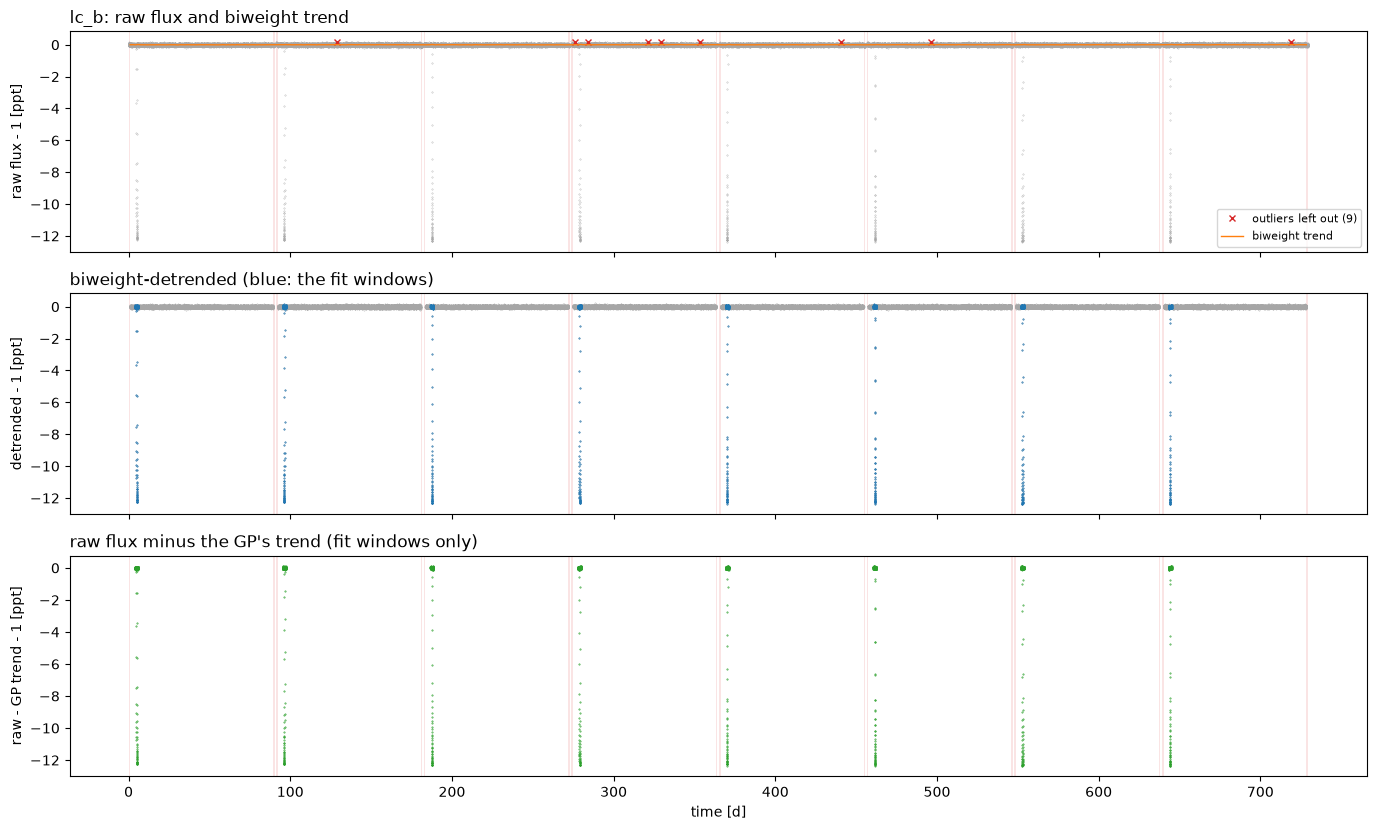

In [15]:
tr_gp = blind.gp_trends(s_gp, gp, gpw["time"], gpw["flux"], gpw["flux_err"])
blind.plot_lightcurve(t, f, T0, P, HALF, bw=bw, gp_trend=(gpw["time"], gpw["flux"], tr_gp["mu_moon"]), bad=outliers,
                      edges=edges,
                      title=f"lc_{NAME}: raw flux and biweight trend")
plt.show()

### 8.1b How well do the two detrenders follow the systematics?

The raw flux around the first transits, zoomed to the out-of-transit level (the transit itself runs off the bottom;
grey band), with the biweight trend (blue) and the GP's trend (red: its posterior mean predicted from the data outside
the transits, with its 1σ band). Below: the raw flux minus each trend in 1-h bins. Wherever the trend follows a
systematic, the residual is flat; wherever a trend follows a real signal next to the transit (a moon), that signal
disappears from the residual. In the fits the trend and the transit model are not separated this way: the biweight is
fixed before the fit, the GP is fitted together with the planet and moon.

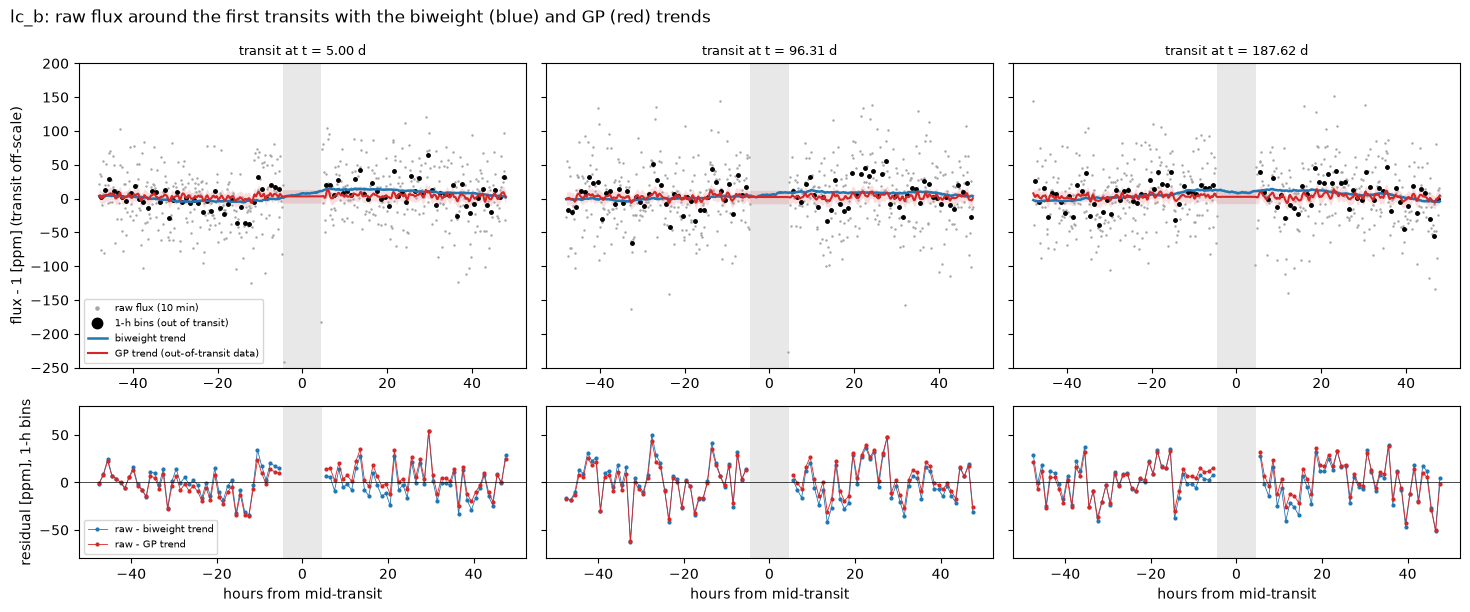

In [16]:
fig = blind.plot_detrending(t, f, bw, gp, sigma, T0, P, T14, n_transits=3, halfwidth=min(2.0, 0.45 * P), bad=bad,
                            title=f"lc_{NAME}: raw flux around the first transits with the biweight (blue) and GP (red) trends")
plt.show()

mean level in the day before the transits: -0.1 ppm; in the day after: +12.0 ppm (+- 1.3 ppm)


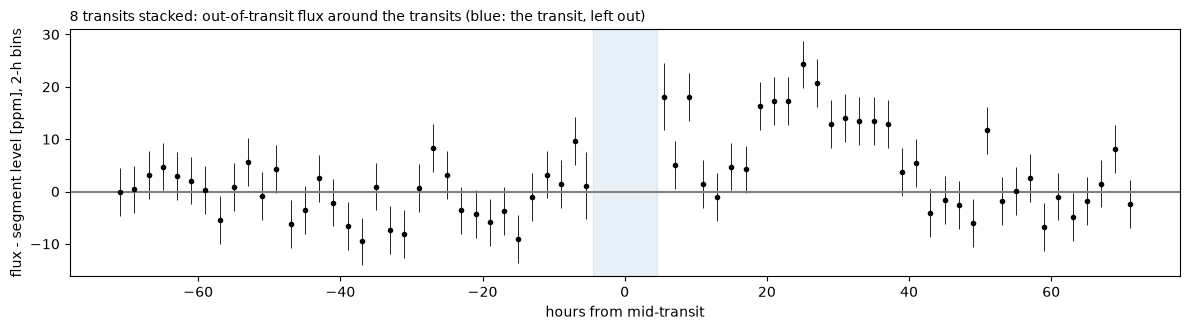

In [17]:
# all transits stacked: is there a systematic tied to the transits? (lc_a: its moon dip after the second transit is
# left out with skip=..., see texts)
fig = blind.plot_post_transit(t, f, sigma, T0, P, T14, [T0 + P * e for e in ft["epoch"]], bad=bad,
                              skip=SKIP_STACK if "SKIP_STACK" in globals() else None)
plt.show()

**The two detrenders agree.** Around the first three transits both trends stay within ±15 ppm of the segment level and
their residuals coincide.

**Post-transit brightening (all six light curves).** The stack of all eight transits shows +12.0 ± 1.3 ppm in the day
after the transits (−0.1 ppm in the day before), fading within ~40 h. At random times the same comparison gives
−0.6 ± 0.4 ppm. It looks like an instrumental or processing memory effect; it is not modelled, and it is too small and
of the wrong sign to create the depth drift.

### 8.2 The transits with the best planet-only and planet+moon models

As in the characterisation tutorial: one column per transit, the data (grey: 10-min, black: 1-h bins) with the
best-fit planet-only (blue) and planet+moon (red) models. Below: the data minus the planet of the planet+moon fit (its
planet component), with the moon's own transit in that fit (red; it can only dim the star). This is what the moon model
attributes to the moon: where the black points follow the red curve, the data contain the moon's dip.

In [18]:
jk = r_gp["jackknife"]
order = np.argsort(jk["dchi2_epochs"])[::-1]
show = sorted(np.array(jk["epochs"])[order[:6]])          # at most 6 transits: those where the moon matters most
tmids = [T0 + P * e for e in show]
PLOT_HALF = min(HALF, 2.5 * T14 + 0.25)     # half-width of the transit plots [d]

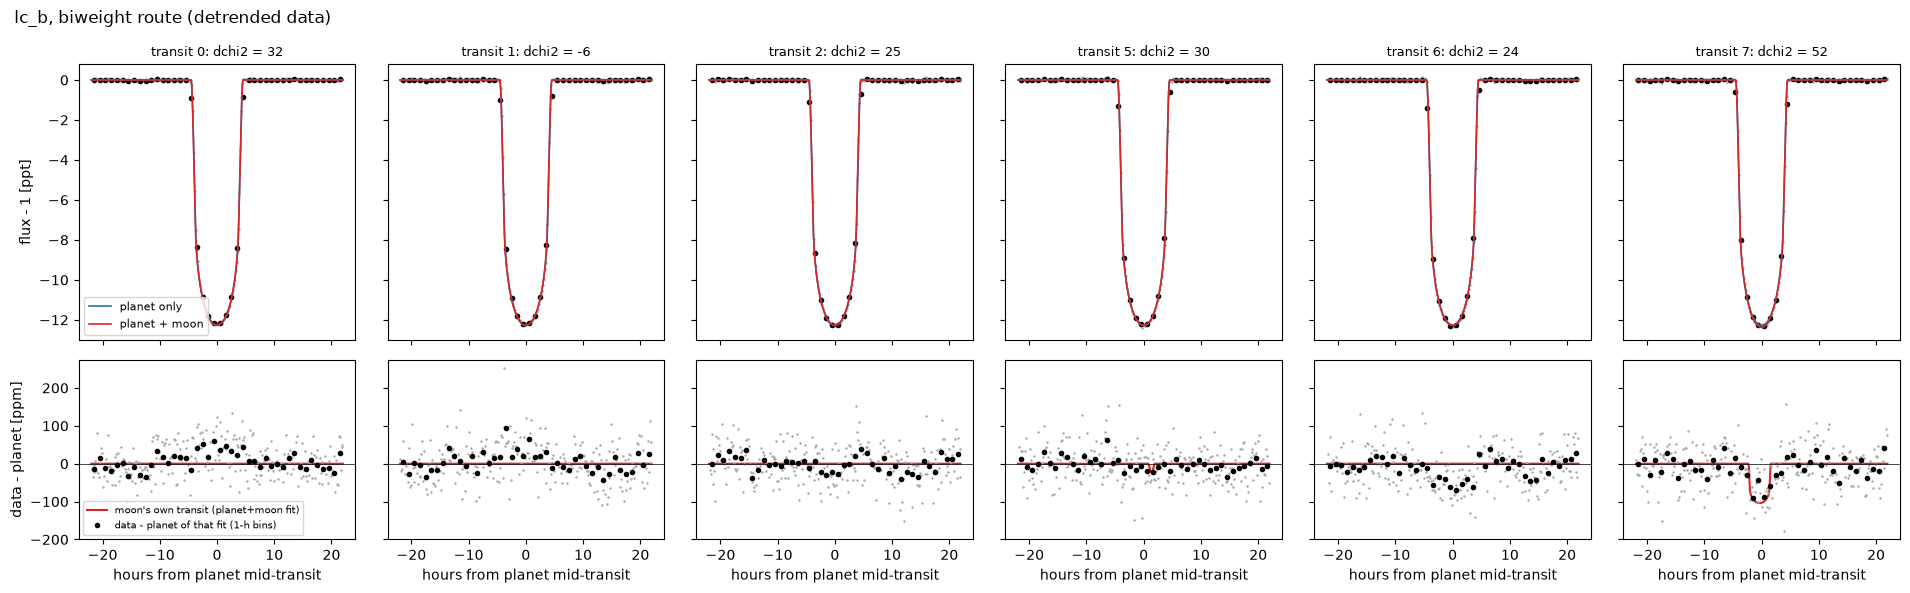

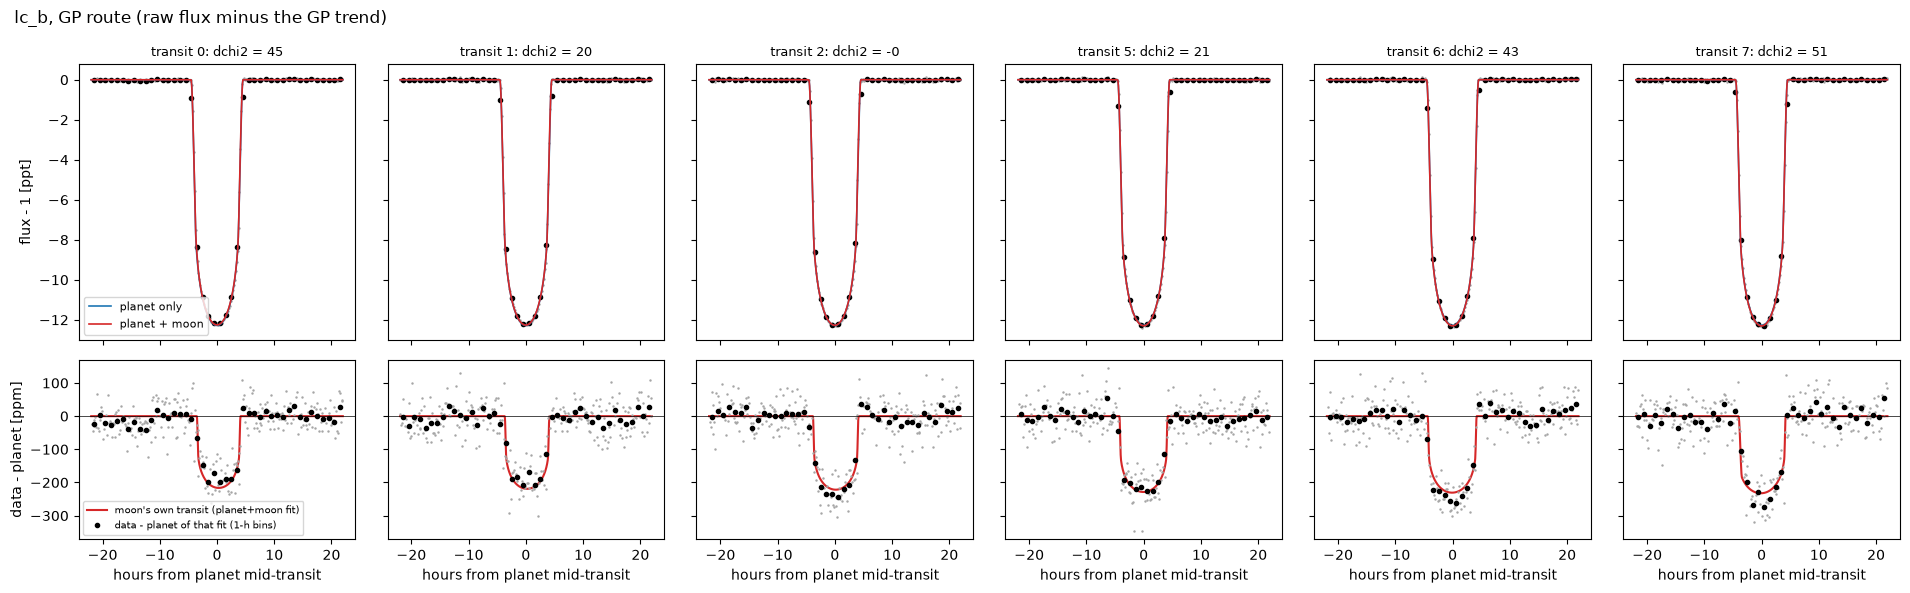

In [19]:
for lab, s, r in (("biweight", s_bw, r_bw), ("GP", s_gp, r_gp)):
    tg, gm, gpl, gpc = blind.model_on_grid(s, tmids, PLOT_HALF)
    jk = r["jackknife"]
    dch = dict(zip(jk["epochs"], jk["dchi2_epochs"]))
    labels = [f"transit {e}: dchi2 = {dch.get(e, np.nan):.0f}" for e in show]
    if lab == "biweight":
        tc, data, fm, fp = blind.best_models(s)
        fpc = blind.best_planet_component(s)
        blind.plot_transits(tc, data, fm, fp, tmids, labels, halfwidth=PLOT_HALF, model_time=tg, model_moon=gm,
                            model_planet=gpl, f_planet_comp=fpc, model_planet_comp=gpc,
                            title=f"lc_{NAME}, biweight route (detrended data)")
    else:
        blind.plot_transits(gpw["time"], gpw["flux"] - tr_gp["mu_moon"], tr_gp["f_moon"], tr_gp["f_planet"], tmids,
                            labels, halfwidth=PLOT_HALF, model_time=tg, model_moon=gm, model_planet=gpl,
                            f_planet_comp=tr_gp["f_planet_comp"], model_planet_comp=gpc,
                            title=f"lc_{NAME}, GP route (raw flux minus the GP trend)")
    plt.show()

**What the models do.** The planet+moon model hardly uses its moon: the moon's own transit (red, bottom) is a ~100 ppm dip at mid-transit in transit 7 and close to zero in the others. What the data minus the planet show instead are changes from transit to transit (+40 ppm inside transit 0, −50 ppm inside transit 6) that no moon dip explains. The moon model's improvement comes from small changes of the planet's transit (its timing, duration and depth through the moon's mass), not from a moon's own transit.

### 8.3 Residuals of the best planet+moon model: spots, artefacts, a wrong transit shape?

If the planet+moon model describes the data, its residuals are noise. Synthetic star spots crossed by the planet would
show as bumps *inside* the transit, a wrong limb-darkening law or exposure time as a pattern at ingress and egress,
and instrumental dips as structure outside. χ²/N compares the residuals with the error bars (for the GP route: the
white-noise part, σ(t) × err_scale, after subtracting the GP trend).

biweight: residuals of the best planet+moon model (chi2/N: 1 = as expected from the error bars)
   transit time   chi2/N in transit   chi2/N outside   mean in-transit residual [ppm]
        5.000          2.66              0.93          +37.0 +- 5.5
       96.312          2.20              1.08          +34.0 +- 6.1
      187.625          1.39              1.18           -3.6 +- 6.0
      278.937          1.37              1.18           +1.5 +- 5.9
      370.250          1.47              1.14          -17.6 +- 5.8
      461.562          1.24              0.89           -9.4 +- 6.4
      552.875          1.82              1.00          -49.0 +- 6.3
      644.188          1.47              1.05           +0.9 +- 6.2
GP: residuals of the best planet+moon model (chi2/N: 1 = as expected from the error bars)
   transit time   chi2/N in transit   chi2/N outside   mean in-transit residual [ppm]
        5.000          1.96              0.94          +11.6 +- 5.4
       96.312          1.61   

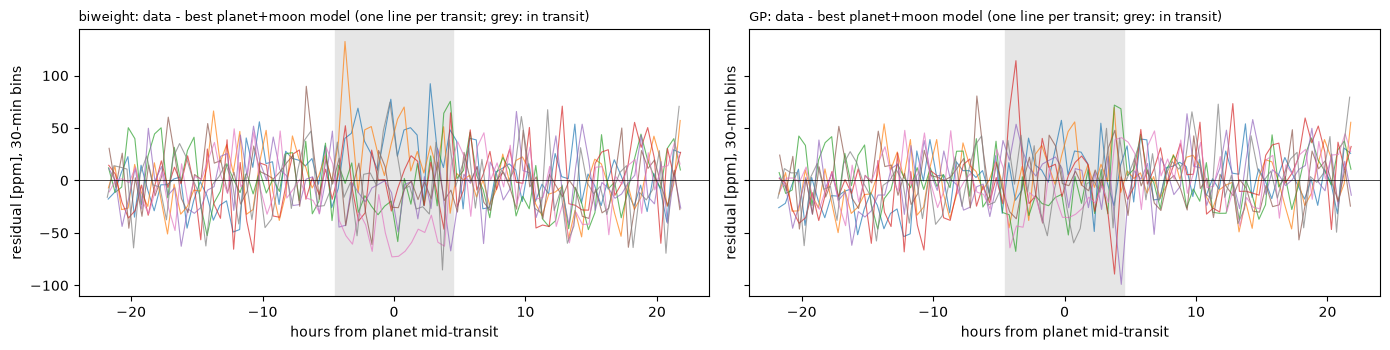

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
tc, data, fm, fp = blind.best_models(s_bw)
lc_err = np.interp(tc, bw["time"], bw["flux_err"])
res_rows_bw = blind.residual_check(tc, data - fm, lc_err, [T0 + P * e for e in ft["epoch"]], T14, PLOT_HALF,
                                   label="biweight", ax=axs[0])
res_rows_gp = blind.residual_check(gpw["time"], gpw["flux"] - tr_gp["mu_moon"] - tr_gp["f_moon"],
                                   gpw["flux_err"] * gp.err_scale, [T0 + P * e for e in ft["epoch"]], T14, PLOT_HALF,
                                   label="GP", ax=axs[1])
plt.tight_layout()
plt.show()

**The planet+moon model does not fit the transits.** Its in-transit χ²/N is 1.2–2.7 per transit (biweight; 1.1–2.0 GP)
against ~1.0 outside, and the mean in-transit residuals change from transit to transit: +37 and +34 ppm in the first two
transits (shallower than the model), −49 ppm in the seventh (deeper). The best planet+moon model leaves the same
systematic pattern as the planet-only model, only smaller.

### 8.4 Posteriors: the moon

Corner plot of the moon's parameters, both routes (blue: biweight, red: GP). r_moon in stellar radii, per_moon in
days, M_moon / M_planet, the inclination i_moon and orientation Ω_moon [deg] of the moon's orbit, and its phase
tau_moon at the first transit. Ω is folded to 0–180° (Ω and Ω + 180° give the same light curves at the transits).

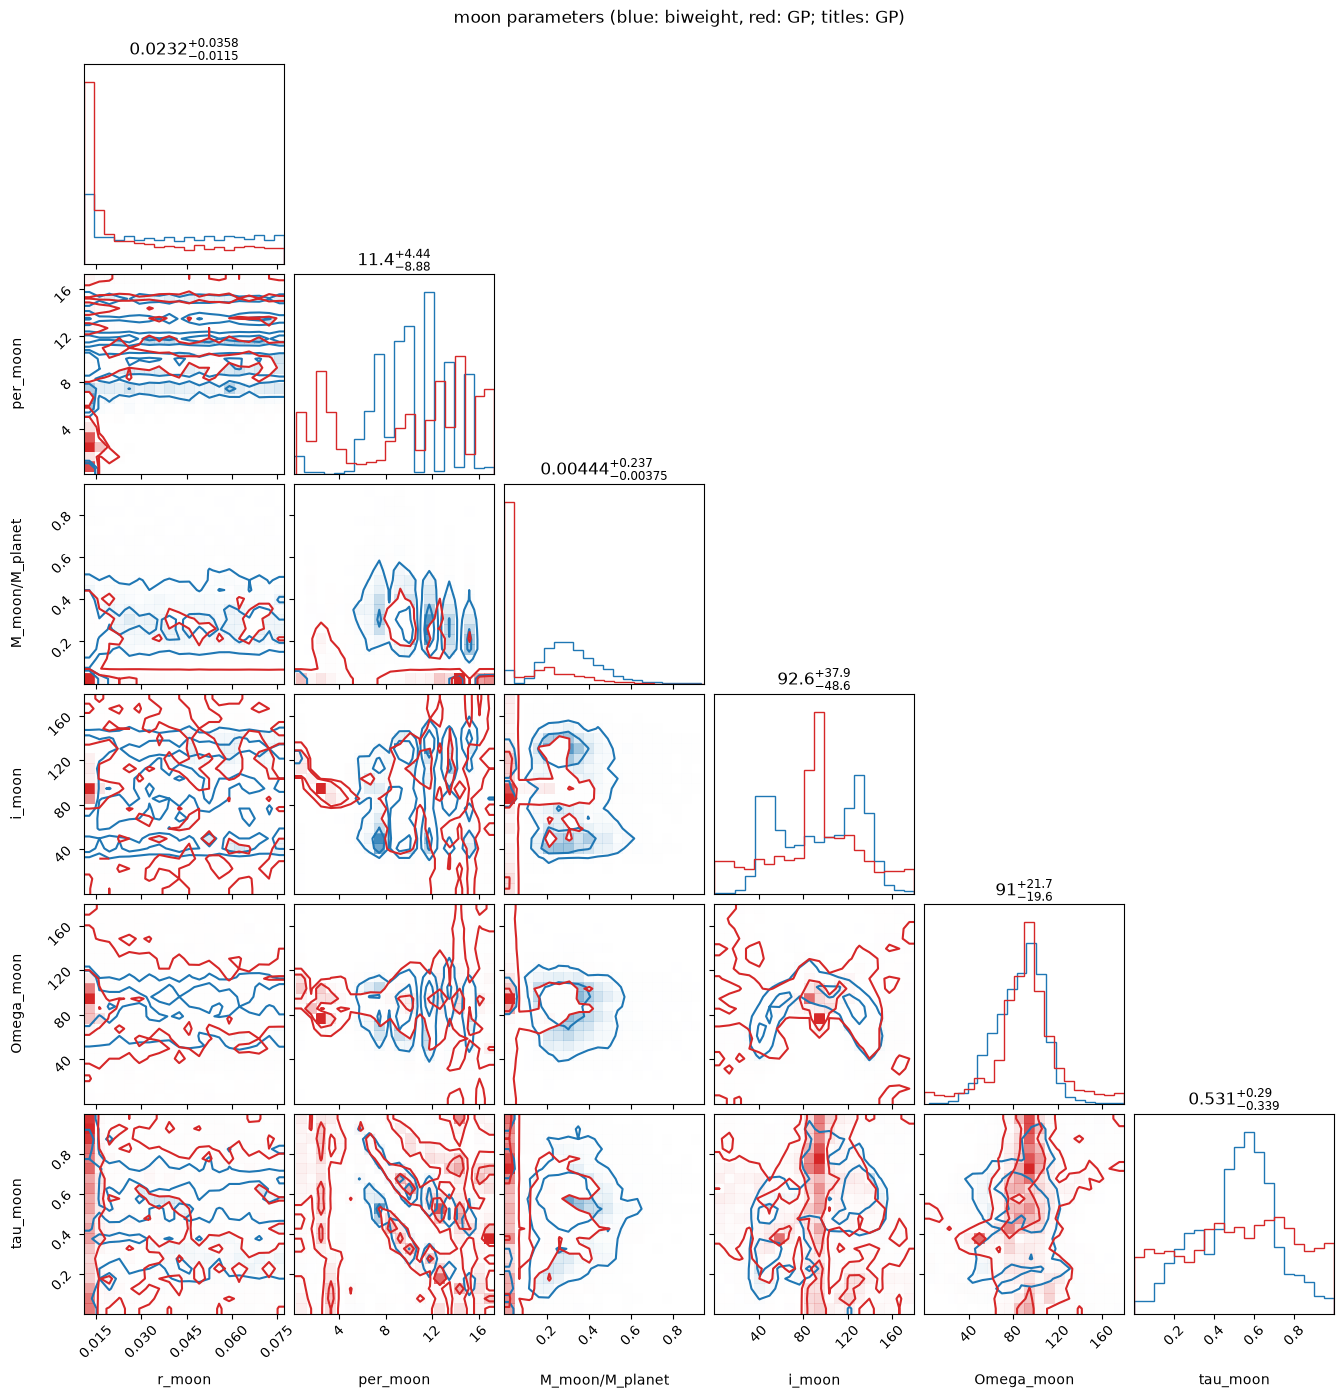

In [21]:
import corner
S_bw, S_gp = blind.samples_dict(r_bw), blind.samples_dict(r_gp)
keys = ["r_moon", "per_moon", "M_moon/M_planet", "i_moon", "Omega_moon", "tau_moon"]
hk = dict(density=True)
fig = corner.corner(np.column_stack([S_bw[k] for k in keys]), labels=keys, color="C0", hist_kwargs=dict(hk, color="C0"),
                    plot_datapoints=False, levels=(0.393, 0.865))
corner.corner(np.column_stack([S_gp[k] for k in keys]), fig=fig, color="C3", hist_kwargs=dict(hk, color="C3"),
              plot_datapoints=False, levels=(0.393, 0.865), show_titles=True, title_fmt=".3g")
fig.suptitle("moon parameters (blue: biweight, red: GP; titles: GP)", y=1.01)
plt.show()

**The moon posterior is not a measurement.**

- **Radius:** 0.012–0.058 stellar radii (68 %), up to the prior's upper end.
- **Mass ratio:** anywhere between 0.0006 and 0.26.
- **Orientation and inclination:** unconstrained.
- **Period:** mostly 8–15 d, near commensurability with the planet's 91.3 days, where the moon's phase at transit
  changes slowly.

A real moon of 1.2–6 Earth radii would show its own dips; none is seen. The posterior describes many ways to bend the
planet's transit shape, not one moon.

### 8.5 Posteriors: planet and star in the planet+moon model

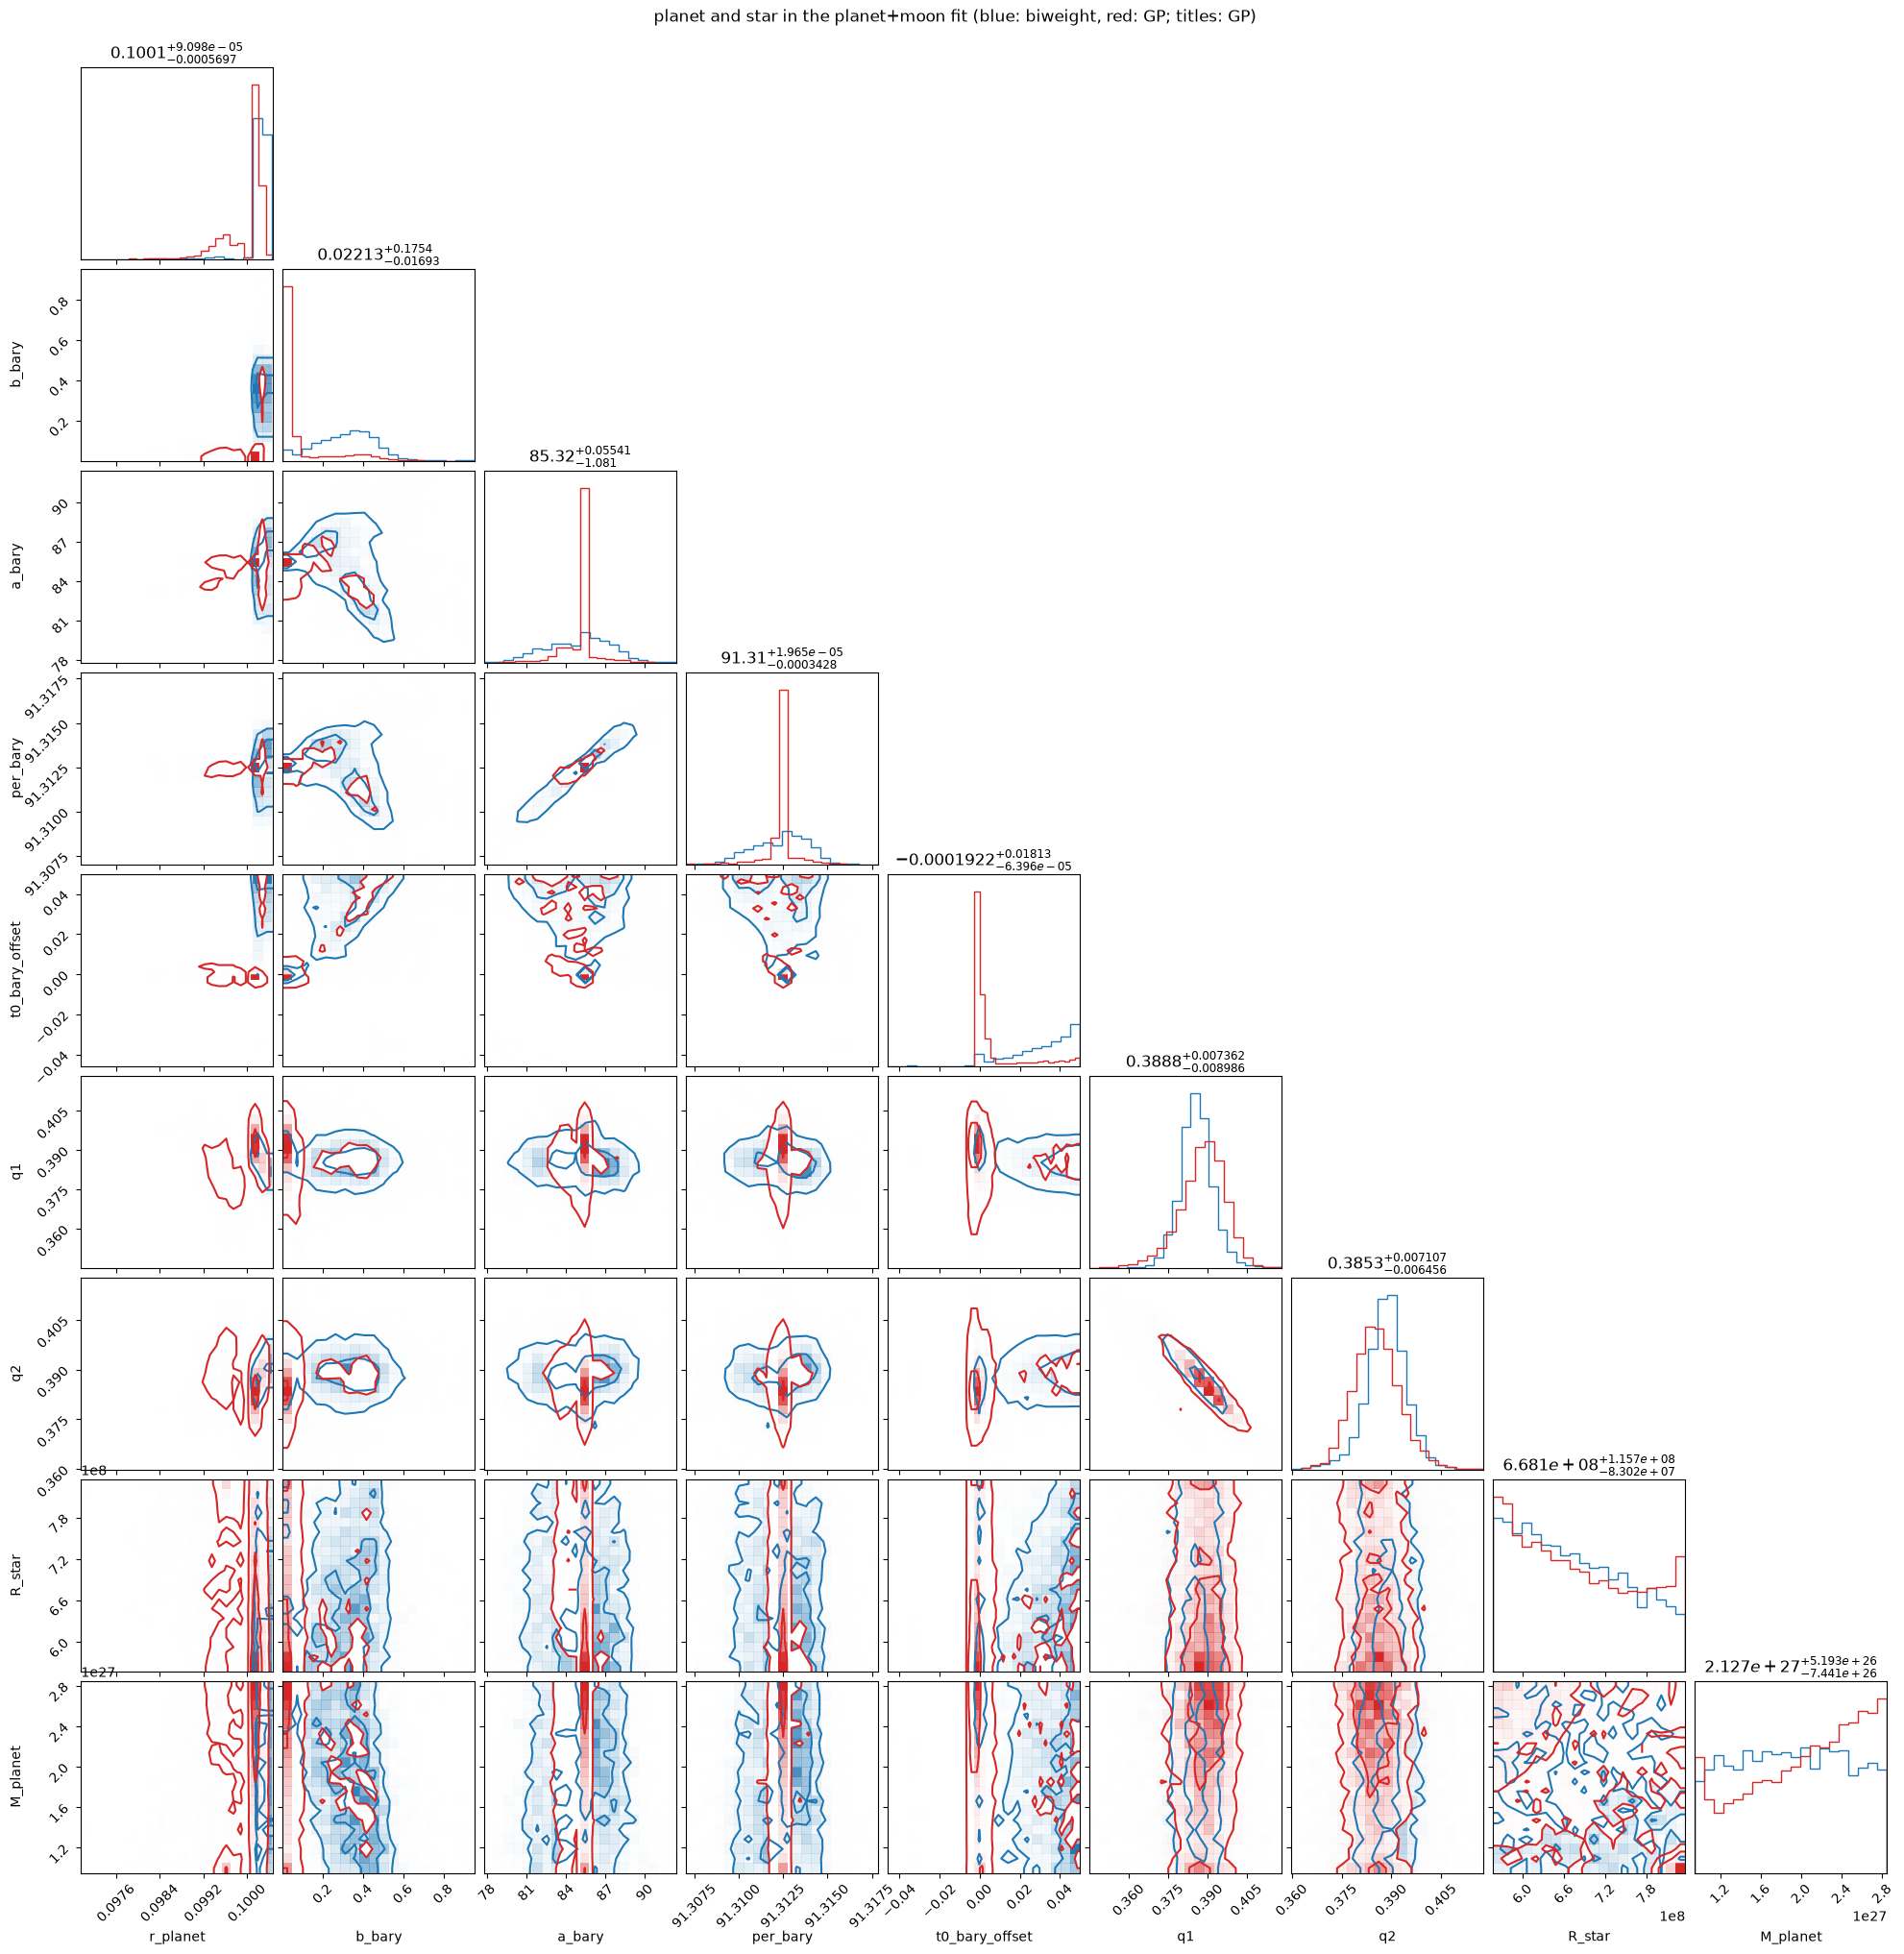

In [22]:
keys = ["r_planet", "b_bary", "a_bary", "per_bary", "t0_bary_offset", "q1", "q2", "R_star", "M_planet"]
fig = corner.corner(np.column_stack([S_bw[k] for k in keys]), labels=keys, color="C0", hist_kwargs=dict(hk, color="C0"),
                    plot_datapoints=False, levels=(0.393, 0.865))
corner.corner(np.column_stack([S_gp[k] for k in keys]), fig=fig, color="C3", hist_kwargs=dict(hk, color="C3"),
              plot_datapoints=False, levels=(0.393, 0.865), show_titles=True, title_fmt=".4g")
fig.suptitle("planet and star in the planet+moon fit (blue: biweight, red: GP; titles: GP)", y=1.01)
plt.show()

**Planet and star.** r_planet = 0.1001 ± 0.0002 stellar radii. In the planet+moon fits the impact parameter moves from
b ≈ 0.02 (planet-only) to 0.3 (biweight), and the epoch offset to the prior's edge (+0.035 d of +0.05): the moon model
changes the planet's geometry to fit the transits' changing depth.

### 8.6 Posteriors: the GP's trend parameters

The fit holds the GP's hyperparameters fixed at their `GP.fit` values. How well do the data constrain them? A short
Metropolis chain over (amp, tau, err_scale) on the residuals of the best planet+moon model in the fit windows
(log-uniform priors over `GP.fit`'s bounds) shows their posterior. `gp_profile` (section 6) refits them for each model.

Metropolis acceptance 0.17; GP.fit values: amp 9.8 ppm, tau 10.0 min, err_scale 0.990


amp 14.0 ppm (68 %: 12.4 ... 15.6); tau median 126 min; err_scale 1.083


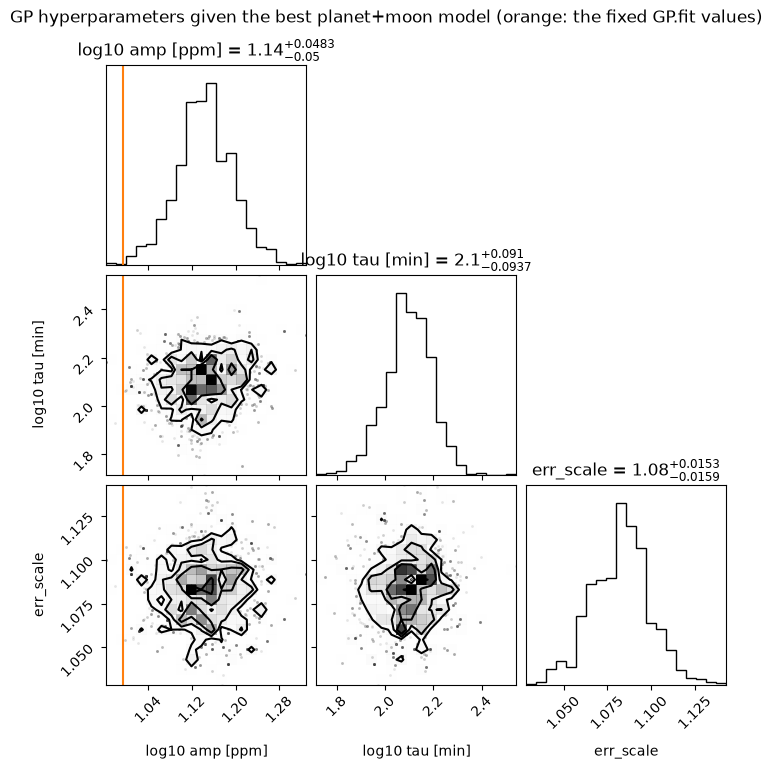

gp_profile: {'dlogz': 8.458805665978844, 'dlogzerr': 1.1876908430930202, 'dlogz_fixed': 26.532815666882925, 'ess_moon': 3.4910947670766497, 'seconds': 2232.940608382225}


In [23]:
resid1 = gpw["flux"] - tr_gp["f_moon"] + 1.0
post = blind.gp_posterior(gp, gpw["time"], resid1, gpw["flux_err"], n_steps=6000, n_burn=1500)
print(f"Metropolis acceptance {post['acceptance']:.2f}; GP.fit values: amp {1e6 * gp.amp:.1f} ppm, "
      f"tau {1440 * gp.tau:.1f} min, err_scale {gp.err_scale:.3f}")
# log axes: where the data constrain the GP weakly, the chain spreads over orders of magnitude
X = np.column_stack([np.log10(1e6 * post["amp"]), np.log10(1440 * post["tau"]), post["err_scale"]])
fig = corner.corner(X, labels=["log10 amp [ppm]", "log10 tau [min]", "err_scale"], show_titles=True,
                    title_fmt=".3g", truths=[np.log10(1e6 * gp.amp), np.log10(1440 * gp.tau), gp.err_scale],
                    truth_color="C1")
lo, med, hi = np.percentile(post["amp"], [16, 50, 84]) * 1e6
print(f"amp {med:.1f} ppm (68 %: {lo:.1f} ... {hi:.1f}); tau median {1440 * np.median(post['tau']):.0f} min; "
      f"err_scale {np.median(post['err_scale']):.3f}")
fig.suptitle("GP hyperparameters given the best planet+moon model (orange: the fixed GP.fit values)", y=1.02)
plt.show()
if r_gp.get("gp_profile"):
    print("gp_profile:", {k: v for k, v in r_gp["gp_profile"].items() if not hasattr(v, "__len__") or isinstance(v, str)})

**The GP hyperparameters in the windows**, given the best planet+moon model: amplitude 14 ppm (12–16), a time scale of
~2 hours (against 10 min outside the windows) and a white-noise factor of 1.08. The GP grows slower in the windows
because the model leaves structure inside the transits (the residuals above).

## 9. The physics of the planet+moon solution

From the posterior samples (GP route): the star's mass follows from a_bary, per_bary and R_star (Kepler's third law),
the moon's orbit from its period and the masses. Radii and masses in Earth and Jupiter units, densities, the moon's
orbit in planet radii and as a fraction of the planet's Hill radius, the Roche limit, and the planet's timing wobble.

In [24]:
Q = blind.physics(S_gp)
blind.print_physics(Q)

  M_star [M_sun]                                                     0.8772   (68 %: 0.5929 ... 1.413)
  R_star [R_sun]                                                     0.9594   (68 %: 0.8398 ... 1.126)
  rho_star [g/cm^3]                                                   1.409   (68 %: 1.356 ... 1.412)
  a_bary [AU]                                                        0.3799   (68 %: 0.3334 ... 0.4453)
  R_planet [R_jup]                                                   0.9347   (68 %: 0.8183 ... 1.096)
  R_planet [R_earth]                                                  10.49   (68 %: 9.183 ... 12.3)
  M_planet [M_jup]                                                     1.12   (68 %: 0.7263 ... 1.395)
  rho_planet [g/cm^3]                                                 1.586   (68 %: 0.9128 ... 2.611)
  R_moon [R_earth]                                                    2.423   (68 %: 1.317 ... 6.09)
  M_moon [M_earth]                                                    1.403  

**The planet** is measured well: 0.100 stellar radii (10 R_earth = 0.89 R_jup) on a 91-day orbit (0.36 AU) around a
star with the Sun's mean density (1.41 g cm⁻³). Its transit deepens by 0.49 % per year.

**The moon** is not measured by the unconverged default fits whose posterior the table shows (radius, mass and density
span orders of magnitude). The fits restricted to the timing solutions (section 10) give three candidate orbits with
almost the same evidence, because eight transits sample the moon's orbit stroboscopically (aliasing):

| P / P_moon | P_moon | moon mass | moon radius | density | orbit | Δln Z |
|---|---|---|---|---|---|---|
| 5.74 | 15.98 d | 0.51 M_earth | 0.69 R_earth | 8.4 g cm⁻³ | 2.0 million km = 0.45 Hill radii | +82.4 |
| 6.26 | 14.54 d | 2.8 M_earth | 0.66 R_earth | 55 g cm⁻³ | 1.8 million km = 0.42 Hill radii | +80.0 |
| 10.26 | 8.87 d | 2.9 M_earth | 0.75 R_earth | 37 g cm⁻³ | 1.0 million km = 0.31 Hill radii | +78.0 |

(maximum-likelihood values; the planet's mass 1.3, 1.2 and 0.5 M_jup, set by the prior.) Only the first is physical:
the other two need densities several times that of iron, at the upper edge of the mass prior. **The 16-day solution**
is a Mars-to-Earth-mass moon (between Mars, 0.11, and Earth), denser than Earth (iron-rich, like Mercury), on a
strongly inclined orbit (Ω = 115°, i = 88°), near the stability limit for prograde moons (~0.5 Hill radii). Its own
dips (~60 ppm) are near the limit of what eight transits can show; it is found through its pull on the planet: the
planet runs ahead of and behind its mean position by up to 0.48 min (~1600 km).

## 10. Further checks: audit and injection-retrieval tests

Four of the six blind light curves gave no moon, so we searched for errors in our own analysis, in two ways:

- an **audit**: cheap checks of each step and assumption (priors, fit windows, noise, detrending, transit model);
- **injection-retrieval tests**: synthetic moons are inserted into the real light curve, the light curve is analysed
  again exactly as in this notebook, and we count how many moons are found.

**What the audit found, for all six light curves:**

- **Priors:** no moon parameter piles up at the upper edge of its prior (radius, period, mass) in any fit, so the data
  do not ask for larger, wider or heavier moons than allowed. Pile-ups at lower edges are expected: the impact
  parameter at 0 (central transits) and, in the no-moon fits, the shortest moon periods (the "hiding places" inside
  the Roche limit).
- **Fit windows:** fully covered by data in every light curve, and no significant dip just outside them (searched out
  to the Hill radius of a 1.5 Jupiter-mass planet).
- **Noise:** the noise σ(t) must be estimated with the transits masked; otherwise the steep ingress and egress
  inflate it by 15–23 % near deep transits (our first round of fits had this bias and was redone). With the mask, the
  errors are calibrated (χ²/N = 0.9–1.04 near the transits).
- **Transit model:** the stacked planet-only residuals show no pattern at ingress, egress or the transit bottom;
  quadratic limb darkening and 10-minute exposures (5 sub-exposures) are adequate at this precision.
- **Detrending:** the biweight keeps deep moon dips (300 ppm: 88–100 % of the dip), but removes 25–30 % of a
  shallow (80 ppm) dip that lasts as long as the transit, i.e. 40–50 % of its Δχ². The GP with its fitted 10-minute
  time scale keeps 62–86 % of a dip's evidence; slower GPs (as in the conservative Bayes factor) keep only 6–13 %,
  which is why the conservative value is a lower bound.
- **`detect` setting:** at its default `recall=0.95`, `detect` sometimes misses the moon model's mode (lc_b). With
  `recall=0.999` (a few seconds more) repeated runs agree; we used it for all injection tests.
- **Two signals no model includes:** a **post-transit brightening** (+5 to +20 ppm for ~40 hours after every transit,
  in all six light curves; it can cancel part of a trailing moon's dip), and a **slow deepening of the transits**
  (most light curves by ~0.2 % per year). A transit that changes with time favours the planet+moon model, because the
  planet-only model has one fixed transit shape.

**A null model for a changing transit.** Pandora's planet-only model has one transit depth for all transits. As a
check, we fitted the biweight data of each light curve (maximum likelihood) with the best planet-only transit whose
depth changes linearly with time (one extra parameter), and with a free depth for each transit, and compared them with
the planet+moon model (nine extra parameters). Δ BIC = Δχ² − (extra parameters) × ln N; positive favours the model
over the planet with a fixed transit:

| light curve | transits | depth change per year | Δχ² linear depth (1) | Δχ² free depth per transit | Δχ² planet+moon (9) | Δ BIC linear depth | Δ BIC planet+moon |
|---|---|---|---|---|---|---|---|
| lc_a | 2 | +0.56 % | 26 | 26 | 1696 | +19 | +1630 |
| lc_b | 8 | +0.46 % | 168 | 198 | 193 | +160 | +124 |
| lc_c | 2 | +0.35 % | 13 | 13 | 25 | +6 | −42 |
| lc_d | 8 | +0.20 % | 12 | 24 | 27 | +4 | −42 |
| lc_e | 2 | +0.28 % | 0.3 | 0.3 | 12 | −6 | −49 |
| lc_f | 32 | +0.43 % | 6 | 51 | 34 | −2 | −37 |

Only lc_a's moon beats a changing transit by far; in lc_c and lc_d a slow deepening explains half of the moon model's
small improvement. (For lc_b the planet+moon fit did not converge; its section 10 shows that timing variations add to
the picture.) **Transit timing:** fitted transit by transit with the planet's own shape, the mid-times of lc_d
(8 transits, ±0.12 min) and lc_f (32 transits, ±0.4 min) scatter close to their errors (χ² 18 for 7 degrees of
freedom, a mild excess of ±0.2 min, and 36 for 31); only lc_b shows strong timing variations (χ² 142 for 7, ±0.48 min).
With two transits (lc_a, lc_c, lc_e) a timing variation cannot be told apart from the period.

**Follow-up tests for lc_b.** The questions: is lc_b's Δln Z caused by a moon, or by the transit's steady deepening?
And what else do the eight transits show?

**1. Can the planet+moon model reproduce the deepening?** (posterior predictive check) We measured the depth of each
of the eight transits (the amplitude of the planet's transit shape), in the data and in 1000 models drawn from each
planet+moon posterior, with noise added as in the data:

![lc_b posterior predictive check](figures/ppc_b.png)

The data deepen by 1.14 × 10⁻³ of the depth per transit (Spearman ρ = +0.90). The biweight posterior's moon (near
P/10, hidden in front of the planet at every transit) gives half of that slope, the GP posterior almost none; no
replicated data set from either posterior is as steep as the data (p < 0.001). A one-parameter linear deepening fits
the eight depths better (χ² 19.5 for 6 degrees of freedom; transit 3 is 3.3σ above the line).

**2. Does a deepening alone, without a moon, give such evidence?** We injected linear depth drifts, and lc_b's own
sequence of eight depths, into lc_d (the same 91-day orbit, no moon), and ran `detect` (15 runs each):

| injected into lc_d (no moon) | depth change per transit | `detect` Δln Z, biweight / GP (median) |
|---|---|---|
| nothing | +3.8 ppm (lc_d's own) | −1 / −3 |
| linear, 1× lc_b's relative rate | +11.7 ppm | +7 / −1 |
| linear, 1.5× | +15.6 ppm | +44 / +9 |
| linear, 2× | +19.6 ppm | +98 / +51 |
| **lc_b's own depth sequence (same ppm)** | +17.7 ppm | **+72 / +43** |
| lc_b, real data | +13.0 ± 1.7 ppm | +62 / +43 |

(The depth changes are measured model-free, from the centre of each transit; for injections they include lc_d's own
+3.8 ppm.) A transit that deepens like lc_b's gives the moon model the same evidence as lc_b, without any moon. The
response is steep: below ~10 ppm per transit `detect` sees nothing, at ~20 ppm it is decisive.

**3. Can a real moon deepen the transit like this?** A moon whose period is close to P/n sits at almost the same phase
at every transit and drifts slowly, so its contribution to the transit can grow from transit to transit.

- In the planet's orbital plane, such moons (1–3 R_earth, P_moon ≈ P/9, 90 injections into lc_d) do produce
  lc_b-like deepenings, but their dips beside the transits are seen as well: `detect` gives +140 to +500 for
  1 R_earth, thousands for larger moons, far more than lc_b's +43 to +62.
- A search over all orientations (Pandora's model fitted to lc_b, P / P_moon = n + δ for n = 6–40) finds that the
  best such moon is ~0.85 R_earth on a nearly polar orbit (it crosses the star only near conjunction), improving χ² by
  154–157 over the planet-only model, against 168 for a one-parameter linear deepening and 198 for a free depth per
  transit. Two of these solutions, continued beyond the data (top: depth per transit; bottom left: the moon's
  contribution in each transit; bottom right: data and model minus the planet, in 1-hour bins):

![lc_b hidden-moon solution, n = 30](figures/strobe_b_n30.png)

![lc_b hidden-moon solution, n = 10](figures/strobe_b_n10.png)

Both predict that the transits become shallower again within 1–3 transits after the end of the data. Full Pandora fits
with the moon prior restricted to this family (P / P_moon = 10 ± 0.07 or 30 ± 0.07, Ω 60–120°, i 75–105°) converge
and give Δln Z = +67.5 and +62.8 (Δχ² 181 and 168). How likely such an orbit is: see the assessment.

**4. Each transit on its own: timing variations.** We fitted each transit separately with the planet's shape (limb
darkening and impact parameter fixed; free depth, duration and mid-time):

![lc_b per-transit fits](figures/pertransit_b.png)

- **Depth:** +11.1 ± 1.0 ppm per transit; transit 2 (the third) lies 4σ above the line.
- **Duration:** T14 = 539.2–540.2 min, nearly constant (+0.08 ± 0.03 min per transit): the deepening does not come
  with a longer transit, as a dilution change would behave, and unlike a drifting impact parameter.
- **Mid-times:** ±0.4 min with errors of ±0.08 min, χ² = 142 for 7 degrees of freedom. lc_d (same orbit, identical
  time stamps) gives 18, lc_f 36 for 31: the errors are right, and the time stamps are not the cause. The values are
  the same from the raw flux with a linear baseline per transit (χ² 145). One sinusoid with a period of 3.86 transits
  (P / P_moon modulo 1 = 0.259) and an amplitude of 0.48 min explains them (χ² 9.6). Transit 2's offset from the
  depth line comes with the largest timing offset (−0.47 min): an early transit leaves negative residuals at ingress
  and positive ones at egress (bottom left panel).

**5. Do moons reproduce the timing?** `detect` on lc_b with the deepening divided out (each transit's depth scaled to
the linear trend's mean): +48 (biweight) and +42 (GP), median of 6 runs; the timing variations alone are decisive
evidence for the moon model. Full Pandora fits with the moon period restricted to three aliases of the timing frequency
(P / P_moon = 5.74, 6.26, 10.26, each ± 0.06; orientation free; moon radius 0.4–3.3 R_earth, mass ≤ 0.01 M_jup) converge
in 2 minutes and give Δln Z = +82.4, +80.0 and +78.0 (Δχ² 212, 208, 208). Their maximum-likelihood models, analysed
like the data, transit by transit:

![lc_b timing moons vs data](figures/ttv_model_b.png)

The timing moons reproduce the mid-times (χ² 142 → 18–19) but not the deepening (145 → 87–104); the hidden moon of
part 3 reproduces the deepening (145 → 34) but not the timing (142 → 122). The light curve holds two signals: timing
variations, which a moon explains, and a deepening, which it does not at the same time.

**Physical causes of a deepening without a moon.** A slowly decreasing dilution (less light from a background source,
or less scattered light, in the aperture) scales the transit and keeps its shape and duration, as observed, and would
also explain why most light curves deepen a little. Unocculted star spots would do the same, but should show
rotational variability, which the light curve does not have. A drifting impact parameter would lengthen the transit
by ~8 minutes, against the observed +0.6 ± 0.2 min (T14, part 4); a growing planet radius is implausible on a two-year time scale.

## 11. Assessment, and what we learned

### Assessment

**lc_b: a moon candidate detected through transit-timing variations, together with an unrelated deepening of the
transit.**

1. **Transit-timing variations** of ±0.48 min (~11σ: χ² 142 for 7 degrees of freedom with a constant ephemeris),
   repeating every 3.9 transits, measured robustly (the same with the biweight and with a linear baseline per transit;
   lc_d, on the same orbit with the same time stamps, shows none). One sinusoid explains them (χ² 9.6). This is the
   stroboscopic signature of a moon: the planet is sampled once per orbit, so a moon period P_moon appears with
   P / P_moon modulo 1 = 0.26 (or 0.74).
2. **Pandora's planet+moon model reproduces the timing variations** (χ² of the mid-times 142 → 18) with moons of
   0.5–3 Earth masses; with the moon periods restricted to the timing solutions the fits converge and give
   Δln Z = +78 to +82 against the planet-only model. With the deepening divided out, `detect` still gives +48 / +42.
3. **The moon is not unique**: three period aliases fit equally well (15.98, 14.54, 8.87 d; more are possible); only
   the 16-day solution has a physical density (0.51 M_earth, 0.69 R_earth, 8.4 g cm⁻³; section 9).
4. **The deepening is a separate effect**: the timing moons reproduce the mid-times but not the deepening (the depth χ²
   falls only from 145 to 87–104); a moon that reproduces the deepening (a hidden, near-polar moon near P/10) does not
   produce the timing variations (122). A deepening without any moon gives the moon model similar evidence when
   injected into lc_d (+72 / +43): it inflates the default fits' Δln Z, but it is not what carries the timing signal.
5. **Alternatives to a moon**: a second planet further out can also make a planet's transits early and late in a
   sinusoidal pattern. A moon also changes the transit's duration, a quarter cycle out of phase with the timing; the
   durations show a variation at the same frequency (0.27 min) at a phase 118° from the timing's, but only at 2σ.

**Verdict: moon candidate (timing variations), strength decisive against the planet-only model, period ambiguous.**
The moon model is strongly favoured over a planet with a fixed transit, but the evidence comes from the planet's
timing, not from the moon's own transits; a perturbing planet is not excluded, and the deepening of the transit needs
another explanation (section 10).

**A caveat on the deepening: a fine-tuned moon.** A moon whose period is very close to a whole fraction of the
planet's (P / P_moon = n + δ, δ ≈ 0.03–0.05), on a nearly polar orbit and hidden in the first transits, would make the
transit deepen as it drifts into view (section 10; Δχ² 154–181 against 168 for a linear deepening). In nature this
needs three coincidences; for a human-generated injection (hand-picked round parameters, or a different convention for
the orbit angles that turns a coplanar orbit into a polar one) it is much less unlikely. It cannot produce the timing
variations at the same time.

### What we learned

1. **Measure each transit's timing with the planet's own shape.** Model-free mid-times (±0.5 min) hid timing variations
   of ±0.48 min that a per-transit fit (±0.08 min) shows at ~11σ. Do this before judging a moon fit.
2. **A Bayes factor compares two models, not "moon or no moon".** Pandora's planet-only model has one transit shape and
   one ephemeris; a slow change of the transit (depth) and timing variations both favour the moon model. Separate them:
   here, dividing out the deepening left Δln Z ≈ +45.
3. **Unconverged fits understate the evidence.** The default full fits stopped at their run limit with +38 (biweight);
   fits restricted to the moon periods the timing allows converged in 2 minutes with +78 to +82.
4. **Stroboscopic sampling makes the moon period ambiguous**: one transit per planet orbit measures only P / P_moon
   modulo 1. The physical aliases (density, Hill stability) narrow it down.
5. **Look at the moon's parameters and the residuals**, not only at Δln Z: a moon that never shows its own dip is found
   through its mass, and its radius is only an upper limit.

## Reproducibility

The run times and versions of this notebook's fits:

In [25]:
import platform
for lab, r in (("biweight", rec_bw), ("GP", rec_gp)):
    print(f"{lab:9s}: planet+moon fit {r['wall'] / 60:6.1f} min, {r['ncall'] / 1e9:.2f} G likelihood calls, "
          f"n_live {r['nlive']}, nsteps {r['nsteps']}, status {r['status']} ({r['date']})")
print("detect wall time: biweight %.1f s, GP %.1f s" % (det_bw["wall"], det_gp["wall"]))
print(platform.platform(), "| python", platform.python_version())
try:
    import numba.cuda
    print("GPU:", str(numba.cuda.get_current_device().name) if numba.cuda.is_available() else "none")
except Exception as e:
    print("GPU: not available", e)

biweight : planet+moon fit  100.5 min, 43.74 G likelihood calls, n_live 2000, nsteps 256, status run_cap (2026-11-21T11:02:45)
GP       : planet+moon fit  174.7 min, 50.11 G likelihood calls, n_live 2000, nsteps 256, status run_cap (2026-11-21T14:37:05)
detect wall time: biweight 21.3 s, GP 24.8 s
Linux-6.1.0-54-amd64-x86_64-with-glibc2.36 | python 3.12.2


GPU: NVIDIA GeForce RTX 5060
